# 3. Когда наблюдения зависимы: единица рандомизации и анализа

Базовый рецепт A/B молча предполагает, что наблюдения, по которым считается метрика, независимы и сами случайно разложены по группам. Он ломается, как только метрику считают не по той единице, которую рандомизировали: CTR по показам при сплите по пользователям, средний чек по покупателям при сплите по магазинам, поездки по пассажирам при сплите по зоне и часу. Тогда обычный t-тест занижает дисперсию в разы и «находит» эффекты, которых нет, а мощность, посчитанная по числу пользователей, оказывается мнимой. Это та же ложная уверенность, что и во встрече 2 про ошибки S и M типов, только приходит она не от малой выборки, а от неверно посчитанного шума. После встречи вы умеете оценить цену кластеризации через ICC и эффект дизайна, выбрать метод анализа под число кластеров и схему рандомизации и спланировать switchback, когда пользователи конкурируют за общий ресурс.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.stats as st
import seaborn as sns
import statsmodels.formula.api as smf
from ipywidgets import FloatSlider, IntSlider, interact
from matplotlib.colors import ListedColormap
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE, ORANGE = '#8172B3', '#DD8452'
ALPHA = 0.05
DATA = 'data/'
rng = np.random.default_rng(42)


def diff_p(a, b):
    """Разность средних b - a, её стандартная ошибка и p-value (критерий Уэлча)."""
    delta = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return delta, se, 2 * st.norm.sf(abs(delta / se))


def rel_effect(a, b):
    """Относительный эффект b/a - 1 и его стандартная ошибка (дельта-метод, независимые группы)."""
    ma, mb = a.mean(), b.mean()
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    return mb / ma - 1, np.sqrt(vb / ma ** 2 + va * mb ** 2 / ma ** 4)


def ratio_effect(num_a, den_a, num_b, den_b):
    """Относительный эффект ratio-метрики sum(num)/sum(den) и его стандартная ошибка (линеаризация)."""
    ra, rb = num_a.sum() / den_a.sum(), num_b.sum() / den_b.sum()

    def var(num, den, r):
        return ((num - r * den) / den.mean()).var(ddof=1) / len(num)

    se = np.sqrt(var(num_b, den_b, rb) / ra ** 2 + var(num_a, den_a, ra) * rb ** 2 / ra ** 4)
    return rb / ra - 1, se


def pct(x, digits=1):
    return f'{100 * x:+.{digits}f}%'


def design_effect(m, icc, cv=0.0):
    """Считает эффект дизайна при среднем размере кластера m и разбросе размеров cv."""
    return 1 + ((cv ** 2 + 1) * m - 1) * icc


def simulate_cluster_means(sizes, icc, reps, local):
    """Генерирует средние кластеров при общей дисперсии 1: строки — симуляции, столбцы — кластеры."""
    sizes = np.asarray(sizes, dtype=float)
    between = local.normal(0, np.sqrt(icc), (reps, len(sizes)))
    within = local.normal(0, 1, (reps, len(sizes))) * np.sqrt((1 - icc) / sizes)
    return between + within


def random_assignment(reps, k, local):
    """Случайно назначает половину кластеров в тест в каждой симуляции."""
    return np.argsort(local.random((reps, k)), axis=1) < k // 2

## Ratio-метрики: числитель и знаменатель по отдельности

Начнём с самой частой ситуации, где единица анализа не совпадает с единицей рандомизации: метрики-отношения. CTR, средний чек, время загрузки страницы считаются по событиям (показам, заказам, загрузкам), а в группы попадают пользователи.

Первая ловушка — в интерпретации. В статье Dmitriev и соавторов о ловушках метрик (Microsoft) блок на главной MSN подняли выше, чтобы до него надо было меньше прокручивать. CTR блока упал на 40%.

**Вопрос.** Блок на главной подняли выше, и в тесте его CTR значимо упал на 40%. Продакт пишет: «Блок стал хуже, откатываем». Что вы ответите и какие цифры попросите, прежде чем решать?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Откатывать по одному CTR нельзя: отношение падает и тогда, когда кликов стало больше, а показов ещё больше. Блок подняли выше, поэтому его видят чаще, и знаменатель почти наверняка вырос. Нужны три цифры: клики по блоку на пользователя, показы на пользователя и клики по всей странице. Если знаменатель значимо изменился, наборы показов в группах разные, и сравнивать само отношение некорректно. Окончательное решение — по OEC: заказам или выручке.

</details>

Оказалось, что клики по блоку выросли на 74%, а показы блока на 200%: знаменатель вырос сильнее числителя. CTR всей страницы при этом не изменился, а выручка выросла, потому что продвинутый блок монетизируется лучше. Эксперимент был хорошим, а CTR блока выглядел катастрофой.

Возьмём сервис доставки еды: то же самое случится, если блок «Акции» на главной поднять выше на экране.

In [2]:
def simulate_module_ctr(rng, n=40000):
    """Блок «Акции» на главной: в тесте его видят чаще, а в среднем он кликабелен хуже. Клики по остальным блокам частично уходят в акции."""
    rows = {}
    for arm, shows, ctr, other in (('контроль', 2.0, .10, 1.80), ('тест', 6.0, .062, 1.63)):
        impressions = rng.poisson(shows, n)
        clicks = rng.binomial(impressions, ctr)
        other_clicks = rng.poisson(other, n)
        rows[arm] = dict(impr=impressions, clicks=clicks, page_clicks=clicks + other_clicks)
    return rows


module = simulate_module_ctr(np.random.default_rng(2))
c, t = module['контроль'], module['тест']
ctr_eff = ratio_effect(c['clicks'], c['impr'], t['clicks'], t['impr'])
clicks_eff = rel_effect(c['clicks'].astype(float), t['clicks'].astype(float))
impr_eff = rel_effect(c['impr'].astype(float), t['impr'].astype(float))
page_eff = rel_effect(c['page_clicks'].astype(float), t['page_clicks'].astype(float))
effects = pd.DataFrame({'метрика': ['CTR блока (клики / показы)', 'клики по блоку на пользователя', 'показы блока на пользователя', 'клики по всей странице на пользователя'],
                        'эффект': [ctr_eff[0], clicks_eff[0], impr_eff[0], page_eff[0]], 'SE': [ctr_eff[1], clicks_eff[1], impr_eff[1], page_eff[1]]})
print(effects.assign(**{'эффект': effects['эффект'].map(pct), 'SE': (100 * effects['SE']).round(1)}).to_string(index=False))

                               метрика  эффект  SE
            CTR блока (клики / показы)  -37.7% 0.8
        клики по блоку на пользователя  +87.1% 2.6
          показы блока на пользователя +200.4% 1.2
клики по всей странице на пользователя   +0.4% 0.5


Числитель (клики) вырос, знаменатель (показы) вырос ещё сильнее, и отношение упало. Часть кликов у блока «Акции» отняли другие блоки, поэтому клики по всей странице почти не изменились. Интерпретация CTR как «блок стал хуже» не работает, когда меняется число показов или набор пользователей, которые блок видели. Решение нужно принимать по OEC (заказам, выручке), а CTR использовать как диагностическую метрику, которую читают вместе с её числителем и знаменателем.

**Вопрос.** Аналитик проверяет CTR так: в группах десятки тысяч показов, клик — это бинарный исход, значит z-тест для двух долей. Рандомизировали при этом пользователей. Корректно ли такое p-value?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет: z-тест для долей считает показы независимыми, а независимы только пользователи. Показы одного пользователя похожи: один кликает охотно, другой никогда, а у кого-то показов в десятки раз больше. Это кластерные данные, где кластер — пользователь, поэтому дисперсия CTR больше, чем у биномиальной доли. Правильная стандартная ошибка считается на уровне пользователя: дельта-методом (линеаризацией) или бутстрапом по пользователям. Насколько ошибается z-тест, зависит от разброса CTR и числа показов на пользователя, ниже это посчитано на A/A.

</details>

### Пользователь как кластер

Проверим на A/A-тестах. У каждого пользователя свой CTR (в среднем 10%) и своё число показов (в среднем около 11, у активных в разы больше). Сравним z-тест по показам и линеаризацию: для пользователя берём $\psi_i = S_i - \hat{R} n_i$, где $S_i$ — его клики, $n_i$ — показы, $\hat{R}$ — CTR группы, и считаем дисперсию по пользователям. Эта же функция `ratio_effect` использовалась выше.

In [3]:
def ctr_aa(n_users=5000, reps=2000, seed=21):
    """A/A-тесты CTR: z-тест по показам против линеаризации по пользователям."""
    local = np.random.default_rng(seed)
    naive, linear, se_ratio = [], [], []
    for _ in range(reps):
        arms = []
        for _arm in range(2):
            impressions = local.poisson(local.lognormal(np.log(8), 0.8, n_users))
            clicks = local.binomial(impressions, local.beta(1, 9, n_users))
            arms.append((clicks, impressions))
        (clicks_a, impr_a), (clicks_b, impr_b) = arms
        ctr_a, ctr_b = clicks_a.sum() / impr_a.sum(), clicks_b.sum() / impr_b.sum()
        se_naive = np.sqrt(ctr_a * (1 - ctr_a) / impr_a.sum() + ctr_b * (1 - ctr_b) / impr_b.sum()) / ctr_a
        effect, se_linear = ratio_effect(clicks_a, impr_a, clicks_b, impr_b)
        naive.append(abs(effect) / se_naive > 1.96)
        linear.append(abs(effect) / se_linear > 1.96)
        se_ratio.append(se_linear / se_naive)
    return pd.Series({'Ложные срабатывания, z-тест по показам': np.mean(naive),
                      'Ложные срабатывания, линеаризация': np.mean(linear),
                      'Во сколько раз честная SE больше': np.mean(se_ratio)})


ctr_aa().round(3).to_frame('A/A, 2000 запусков')

,"A/A, 2000 запусков"
"Ложные срабатывания, z-тест по показам",0.244
"Ложные срабатывания, линеаризация",0.052
Во сколько раз честная SE больше,1.703


z-тест по показам ошибается примерно в четверти A/A-тестов вместо 5%: его стандартная ошибка в 1.7 раза меньше честной. Линеаризация держит уровень. Механизм общий для всей встречи: **единица анализа (показ) не совпадает с единицей рандомизации (пользователь)**, и наблюдения внутри единицы рандомизации зависимы. Пока кластер — это пользователь, у нас тысячи кластеров, и дельта-метод спасает. Дальше кластером станет город, школа или магазин, а затем пара «зона–час», и кластеров окажется десятки.

## Зачем назначать воздействие группам

В обычном A/B-тесте мы случайно назначаем воздействие пользователю. В **кластерном A/B-тесте (cluster randomized trial)** случайно назначается целая группа: город, магазин, школа, сообщество в социальном графе. Все внутри группы получают одно условие, а метрику мы часто по-прежнему считаем по пользователям.

Посмотрим на разницу.

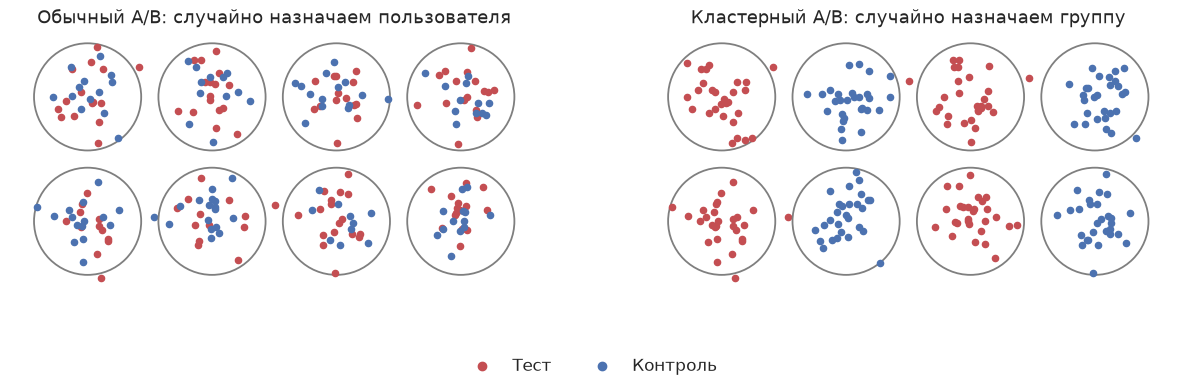

In [4]:
def plot_assignment(ax, by_cluster, title, seed=3):
    local = np.random.default_rng(seed)
    centers = np.array([(x, y) for x in range(4) for y in range(2)], dtype=float) * 2.6
    arms = local.permutation([0, 0, 0, 0, 1, 1, 1, 1])
    for center, arm in zip(centers, arms):
        points = center + local.normal(0, 0.42, (28, 2))
        treated = np.full(28, arm == 1) if by_cluster else local.random(28) < 0.5
        ax.add_patch(plt.Circle(center, 1.12, fill=False, color=GRAY, lw=1.3))
        ax.scatter(*points[treated].T, color=RED, s=20)
        ax.scatter(*points[~treated].T, color=BLUE, s=20)
    ax.set_aspect('equal')
    ax.set_axis_off()
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
plot_assignment(axes[0], False, 'Обычный A/B: случайно назначаем пользователя')
plot_assignment(axes[1], True, 'Кластерный A/B: случайно назначаем группу')
axes[1].scatter([], [], color=RED, label='Тест')
axes[1].scatter([], [], color=BLUE, label='Контроль')
fig.legend(*axes[1].get_legend_handles_labels(), loc='lower center', ncol=2, frameon=False);

Есть три равноправные причины так делать.

**1. Группы даны заранее, и делить внутри них невозможно или бессмысленно.** В магазине нельзя показать одну выкладку одному покупателю, а другую соседнему. Учитель работает с классом целиком, а курьеры обслуживают весь район. Здесь кластер — это физическая или организационная единица.

**2. Заражение и интерференция.** Пользователи влияют друг на друга, и контроль получает часть воздействия. Это нарушение SUTVA: исход пользователя зависит не только от его собственной группы. Подробнее о нём — во второй части встречи, про switchback. Оно бывает разным:

* **заражение:** контроль узнаёт о воздействии, например промокод передают внутри компании или семьи;
* **сетевой эффект:** ценность продукта зависит от того, есть ли функция у друзей, например звонки в мессенджере;
* **конкуренция за ресурс:** на маркетплейсе тестовые продавцы забирают покупателей у контрольных.

Если часть $c$ контрольной группы получает полное воздействие, наблюдаемый эффект равен $(1-c)\tau$, то есть размывается. А при конкуренции за ресурс смещение может быть и вверх: тестовая группа выигрывает за счёт контрольной. В [кейсе Avito](https://habr.com/ru/companies/avito/articles/1043880/) тест по продавцам показал рост 88%, а настоящий эффект был 36%.

**3. Воздействие нельзя таргетировать на человека.** Реклама на ТВ и наружная реклама, цены и налоги в регионе, доставка в городе. Здесь кластер — география. Этот случай выделяют отдельно как **геоэксперименты**: кластеров мало, они очень разные, и нужны свои методы.

Кластерный дизайн не единственный выход.

| Ситуация | Что подходит |
| :--- | :--- |
| Пользователи независимы, можно таргетировать | Обычный A/B |
| Влияние через общий ресурс, эффект быстрый | Switchback (вторая часть встречи) |
| Сравниваем ранжирование в одной выдаче | Interleaving |
| Есть группы, граф или география, эффект может быть долгим | Кластерный A/B |
| Единиц очень мало, рандомизация невозможна | Синтетический контроль |

Кластеризация убирает смещение между группами, но за это мы платим. Главная мысль этой части: **мощность теста определяется в первую очередь числом кластеров, а не числом пользователей**.

## Цена кластеризации: ICC и эффект дизайна

### Внутриклассовая корреляция

Пользователи одного кластера похожи: у них общий город, магазин или учитель. Запишем исход $i$-го пользователя в кластере $j$:

$$
Y_{ij} = \mu + u_j + e_{ij}, \qquad u_j \sim N(0, \sigma_u^2), \quad e_{ij} \sim N(0, \sigma_e^2)
$$

Здесь $u_j$ — общая добавка кластера. Доля дисперсии, которая приходится на различия между кластерами, называется **внутриклассовой корреляцией (intracluster correlation, ICC)**:

$$
\rho = \frac{\sigma_u^2}{\sigma_u^2 + \sigma_e^2}
$$

Это же корреляция исходов двух пользователей одного кластера. Значения обычно малы: в медицине и образовании часто порядка 0.01–0.2. Но малый ICC не значит малую проблему, потому что он умножается на размер кластера.

### Эффект дизайна

Среднее кластера размера $m$ имеет дисперсию

$$
\text{Var}(\bar{Y}_j) = \sigma_u^2 + \frac{\sigma_e^2}{m} = \frac{\sigma^2}{m}\big(1 + (m-1)\rho\big), \qquad \sigma^2 = \sigma_u^2 + \sigma_e^2
$$

Если бы $m$ пользователей были независимы, дисперсия была бы $\sigma^2/m$. Значит, кластеризация увеличивает дисперсию в

$$
DE = 1 + (m-1)\rho
$$

раз. Это **эффект дизайна (design effect)**. Эффективный размер выборки равен $n / DE$. При ICC 0.01 и 1000 пользователях в кластере $DE \approx 11$: из 100 000 пользователей остаётся эффективных около 9 000.

Если размеры кластеров разные, используют оценку с весами по размеру, то есть общее среднее по пользователям. Для неё формулу легко вывести. Дисперсия равна $\frac{1}{N^2}\sum_j n_j \sigma^2 (1 + (n_j - 1)\rho)$, откуда

$$
DE = 1 + \bigg(\frac{\sum n_j^2}{N} - 1\bigg)\rho = 1 + \big((CV^2 + 1)\bar{m} - 1\big)\rho
$$

где $CV$ — коэффициент вариации размеров кластеров. Эта формула известна как поправка Элдриджа и соавторов (2006). По [обзору](https://pmc.ncbi.nlm.nih.gov/articles/PMC8320970/) неравными размерами можно пренебречь при $CV$ ниже 0.23, а большие кластеры сильно увеличивают дисперсию. Проверим обе формулы симуляцией.

In [5]:
def simulated_de(sizes, icc, reps=200_000, seed=1):
    local = np.random.default_rng(seed)
    means = simulate_cluster_means(sizes, icc, reps, local)
    sizes = np.asarray(sizes, dtype=float)
    pooled = (means * sizes).sum(axis=1) / sizes.sum()
    return pooled.var() * sizes.sum()


rows = []
for name, sizes in [('Равные, m = 100', np.full(40, 100)),
                    ('CV = 0.5', 100 * (1 + 0.5 * st.norm.ppf((np.arange(40) + 0.5) / 40))),
                    ('CV около 1', np.exp(st.norm.ppf((np.arange(40) + 0.5) / 40) * 0.95 + 4))]:
    sizes = np.maximum(sizes, 5).round()
    cv = sizes.std() / sizes.mean()
    for icc in [0.01, 0.05]:
        rows.append({'Размеры': name, 'CV': cv, 'ICC': icc, 'DE по формуле': design_effect(sizes.mean(), icc, cv), 'DE в симуляции': simulated_de(sizes, icc)})
pd.DataFrame(rows).round(2)

,Размеры,CV,ICC,DE по формуле,DE в симуляции
0,"Равные, m = 100",0.00,0.01,1.99,1.98
1,"Равные, m = 100",0.00,0.05,5.95,5.94
2,CV = 0.5,0.48,0.01,2.23,2.23
3,CV = 0.5,0.48,0.05,7.14,7.15
4,CV около 1,1.05,0.01,2.74,2.74
5,CV около 1,1.05,0.05,9.71,9.73


Формула совпала с симуляцией: например, 9.71 и 9.73 при ICC 0.05 и $CV \approx 1$. Неравные размеры заметно ухудшают ситуацию: при тех же ICC и среднем размере эффект дизайна равен 9.7 вместо 6.

Теперь посмотрим, что это значит для теста. Подвигайте ICC и размер кластера. Эффект равен нулю: мы видим только шум, сравнивая две половины из 40 кластеров. Для сравнения показано распределение при том же числе пользователей и индивидуальной рандомизации.

In [6]:
def plot_noise(ax, icc, m, k=40, reps=4000, seed=2):
    local = np.random.default_rng(seed)
    means = simulate_cluster_means(np.full(k, m), icc, reps, local)
    treated = random_assignment(reps, k, local)
    estimate = (means * treated).sum(axis=1) / (k // 2) - (means * ~treated).sum(axis=1) / (k // 2)
    individual = local.normal(0, np.sqrt(4 / (k * m)), reps)
    bins = np.linspace(-1, 1, 61) * max(4 * estimate.std(), 0.02)
    ax.hist(individual, bins=bins, color=GRAY, alpha=0.6, label='Индивидуальная')
    ax.hist(estimate, bins=bins, color=BLUE, alpha=0.6, label='Кластерная')
    ax.set_title(f'ICC = {icc}, m = {m}: DE = {design_effect(m, icc):.1f}, SD выросло в {estimate.std() / individual.std():.1f} раза', fontsize=12)
    ax.set_xlabel('Оценка эффекта при нулевом настоящем эффекте')
    ax.legend(fontsize=10)


def noise_demo(icc=0.02, m=200):
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    plot_noise(ax, icc, m)
    plt.show()


interact(noise_demo,
         icc=FloatSlider(value=0.02, min=0, max=0.2, step=0.01, description='ICC'),
         m=IntSlider(value=200, min=10, max=2000, step=10, description='Размер'));

interactive(children=(FloatSlider(value=0.02, description='ICC', max=0.2, step=0.01), IntSlider(value=200, des…

Статичная версия для трёх сочетаний.

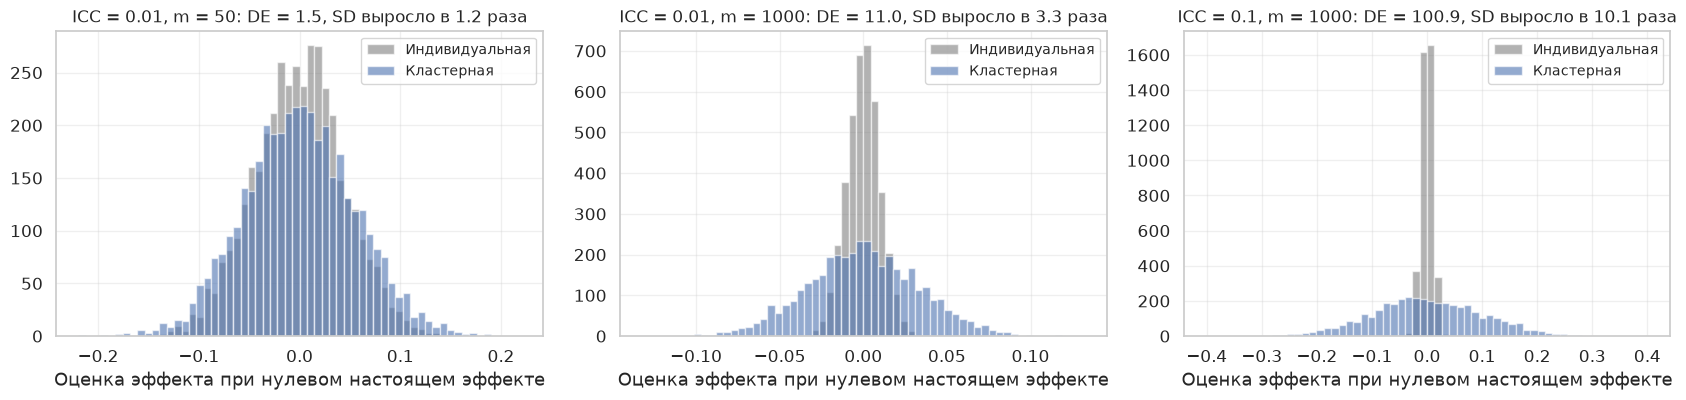

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (icc, m) in zip(axes, [(0.01, 50), (0.01, 1000), (0.1, 1000)]):
    plot_noise(ax, icc, m)
plt.tight_layout()

**Вопрос.** Вы рандомизировали города, в каждом примерно по 1000 активных пользователей. ICC метрики между городами по истории всего 0.002. Коллега предлагает «не усложнять» и посчитать обычный t-тест по пользователям: поправка ведь копеечная. Насколько он ошибётся: 5% ложных срабатываний превратятся в 6% или в 25%?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Скорее в 25%: малый ICC умножается на размер кластера. Эффект дизайна равен

$$DE = 1 + (m-1)\rho$$

и при 1000 пользователях в городе и ICC 0.002 он около 3. Значит, t-тест по пользователям занижает дисперсию втрое, а стандартную ошибку в 1.7 раза. Статистика, которая при честной ошибке была бы 1.1, выглядит как 1.96, и порог пробивается примерно в четверти A/A-тестов. При ICC 0.01 было бы уже больше половины. Проверим симуляцией ниже.

</details>

### Что будет, если не заметить кластеры

Самая частая ошибка — назначить воздействие кластерам, а затем посчитать обычный t-тест по пользователям. Он считает пользователей независимыми, поэтому занижает дисперсию примерно в $DE$ раз. Посчитаем ошибку первого рода при $\alpha = 5\%$.

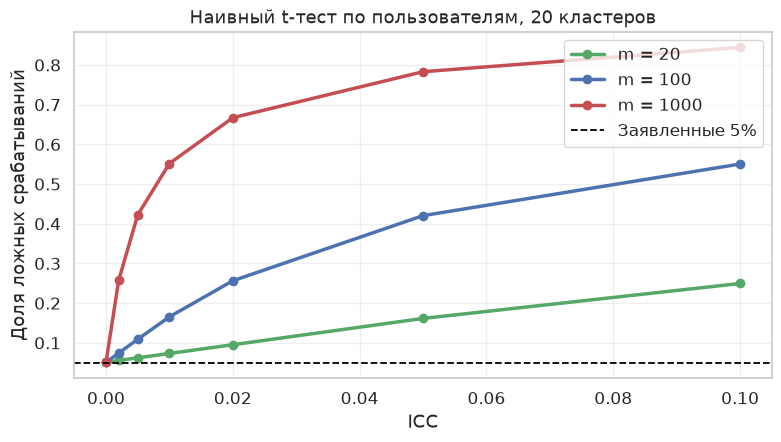

In [8]:
def naive_false_positive(icc, m, k=20):
    """Считает долю ложных срабатываний t-теста по пользователям по формуле занижения дисперсии."""
    return 2 * st.norm.sf(1.96 / np.sqrt(design_effect(m, icc)))


def simulated_false_positive(icc, m, k=20, reps=100_000, seed=4):
    local = np.random.default_rng(seed)
    means = simulate_cluster_means(np.full(k, m), icc, reps, local)
    treated = random_assignment(reps, k, local)
    estimate = (means * treated).sum(axis=1) / (k // 2) - (means * ~treated).sum(axis=1) / (k // 2)
    naive_se = np.sqrt(4 / (k * m))
    return np.mean(np.abs(estimate / naive_se) > 1.96)


iccs = np.array([0, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1])
fig, ax = plt.subplots(figsize=(9, 4.5))
for m, color in zip([20, 100, 1000], [GREEN, BLUE, RED]):
    ax.plot(iccs, [simulated_false_positive(icc, m) for icc in iccs], 'o-', color=color, lw=2.5, label=f'm = {m}')
ax.axhline(0.05, color='black', ls='--', lw=1.3, label='Заявленные 5%')
ax.set_xlabel('ICC')
ax.set_ylabel('Доля ложных срабатываний')
ax.set_title('Наивный t-тест по пользователям, 20 кластеров')
ax.legend();

Ошибка огромна даже при крошечном ICC. При ICC 0.002 и 1000 пользователях в кластере ложных срабатываний 26%, при ICC 0.01 уже 55%, а при ICC 0.05 почти 80%. ICC 0.01 выглядит пренебрежимо, но умножается на 1000.

**Вопрос.** Тест идёт в 60 городах, по 30 в каждой группе, и MDE не устраивает. Продакт предлагает подключить к тесту вдвое больше пользователей в тех же городах: «трафика станет в два раза больше». Альтернатива — добавить новые города, но это дольше и дороже. Что вы посоветуете?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Добавлять города, если это хоть как-то возможно: при фиксированном числе кластеров рост пользователей внутри упирается в предел. Дисперсия разницы средних состоит из межкластерной части, которая делится только на число кластеров, и внутрикластерной, которая делится на число пользователей. Когда пользователей в кластере много, внутрикластерная часть уже мала, и удвоение трафика почти ничего не даёт. Удвоение трафика оправдано, только если кластеры маленькие или ICC почти нулевой, и это стоит посчитать по истории до разговора с продактом.

</details>

### Мощность: число кластеров важнее их размера

При $k$ кластерах на группу размера $m$ минимальный обнаруживаемый эффект равен

$$
MDE = (t_{1-\alpha/2} + t_{1-\beta}) \sqrt{\frac{2\sigma^2 (1 + (m-1)\rho)}{k m}}
$$

где квантили берутся из распределения Стьюдента с $2(k-1)$ степенями свободы. Это стандартная поправка для кластерных испытаний: при малом $k$ она заметна. Заметьте, что при $m \to \infty$

$$
MDE \to (t_{1-\alpha/2} + t_{1-\beta}) \sqrt{\frac{2\sigma^2\rho}{k}}
$$

То есть рост числа пользователей внутри кластеров упирается в предел, который можно сдвинуть только числом кластеров. Посмотрим на это: сравним рост $m$ при фиксированном $k$ и рост $k$ при фиксированном общем числе пользователей.

In [9]:
def cluster_mde(k, m, icc, power=0.8, alpha=0.05):
    """Считает MDE в стандартных отклонениях для k кластеров на группу размера m."""
    df = 2 * (k - 1)
    return (st.t.ppf(1 - alpha / 2, df) + st.t.ppf(power, df)) * np.sqrt(2 * (1 + (m - 1) * icc) / (k * m))


def plot_mde(axes, icc):
    sizes = np.geomspace(10, 100_000, 60)
    for k, color in zip([10, 30, 100], [RED, BLUE, GREEN]):
        axes[0].plot(sizes, cluster_mde(k, sizes, icc), color=color, lw=2.5, label=f'k = {k} на группу')
        axes[0].axhline(cluster_mde(k, 1e12, icc), color=color, ls=':', lw=1.2)
    axes[0].set_xscale('log')
    axes[0].set_yscale('log')
    axes[0].set_yticks([0.03, 0.05, 0.1, 0.2, 0.4], ['0.03', '0.05', '0.1', '0.2', '0.4'])
    axes[0].minorticks_off()
    axes[0].set_xlabel('Пользователей в кластере')
    axes[0].set_ylabel('MDE, стандартные отклонения')
    axes[0].set_title(f'ICC = {icc}: при фиксированном числе кластеров рост упирается в предел', fontsize=12)
    axes[0].legend(fontsize=10)

    clusters = np.array([5, 10, 20, 50, 100, 200, 500, 1000, 2000])
    for total, color in zip([20_000, 200_000], [BLUE, RED]):
        axes[1].plot(clusters, cluster_mde(clusters, total / clusters, icc), 'o-', color=color, lw=2.5, label=f'{total:,} пользователей на группу'.replace(',', ' '))
    axes[1].set_xscale('log')
    axes[1].set_yscale('log')
    axes[1].set_yticks([0.01, 0.03, 0.1, 0.3], ['0.01', '0.03', '0.1', '0.3'])
    axes[1].minorticks_off()
    axes[1].set_xlabel('Кластеров на группу')
    axes[1].set_title('При том же числе пользователей лучше больше мелких кластеров', fontsize=12)
    axes[1].legend(fontsize=10)


def mde_demo(icc=0.02):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    plot_mde(axes, icc)
    plt.tight_layout()
    plt.show()


interact(mde_demo, icc=FloatSlider(value=0.02, min=0.001, max=0.2, step=0.001, readout_format='.3f', description='ICC'));

interactive(children=(FloatSlider(value=0.02, description='ICC', max=0.2, min=0.001, readout_format='.3f', ste…

Статичная версия при ICC 0.02.

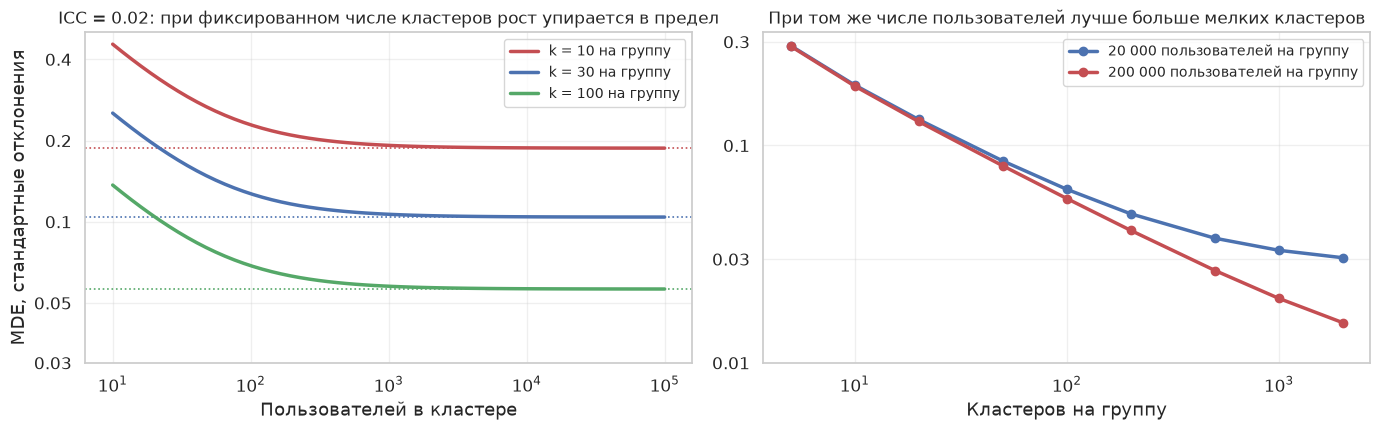

k = 30, m = 1000: DE = 21, MDE = 0.107 SD
k = 30, m = 10000: DE = 201, MDE = 0.104 SD
k = 300, m = 100: DE = 3, MDE = 0.040 SD
k = 300, m = 1000: DE = 21, MDE = 0.033 SD


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_mde(axes, 0.02)
plt.tight_layout()
plt.show()

for k, m in [(30, 1000), (30, 10_000), (300, 100), (300, 1000)]:
    print(f'k = {k}, m = {m}: DE = {design_effect(m, 0.02):.0f}, MDE = {cluster_mde(k, m, 0.02):.3f} SD')

Увеличение кластеров с 1000 до 10 000 пользователей почти ничего не даёт: MDE падает с 0.107 до 0.104. Увеличение числа кластеров с 30 до 300 снижает его втрое, до 0.033. На одних и тех же 30 000 пользователей на группу вариант из 300 кластеров по 100 человек даёт 0.040, а вариант из 30 кластеров по 1000 человек только 0.107.

Эта оценка опирается на постоянный ICC. При разбиении на более мелкие кластеры ICC обычно меняется, а главное, для интерференции мелкие кластеры хуже изолированы. Этот компромисс разобран ниже.

ICC при планировании берут из исторических данных: проведите A/A на прошлом периоде или оцените его дисперсионным анализом. Этот приём показан в разделе про школы.

**Вопрос.** Новая выкладка тестируется в 60 магазинах очень разного размера. Аналитик А сравнивает средние чеки магазинов t-тестом по 60 значениям. Аналитик Б делит суммарную выручку групп на суммарное число покупателей. Оценки эффекта заметно разошлись. Кто прав и что вы скажете продакту?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Оба могут быть правы: они оценивают разные величины. Средняя разница по магазинам — это эффект на магазин, где маленький магазин весит столько же, сколько гипермаркет. Отношение сумм — эффект на покупателя. Если эффект зависит от размера магазина, эти величины расходятся, и ни одна оценка не ошибочна. Продакту обычно нужен эффект на покупателя, потому что деньги приносят покупатели, но он шумнее: большие магазины забирают вес. Главное — выбрать оцениваемую величину до теста, а не по тому, какая оценка вышла значимой.

</details>

## Единица рандомизации и единица анализа

В кластерном тесте **единица рандомизации (кластер) не совпадает с единицей анализа (пользователь)**. Это порождает два вопроса.

**Какой эффект мы оцениваем?** Есть две разные величины:

$$
\tau_{user} = \frac{\sum_j n_j \tau_j}{\sum_j n_j}, \qquad \tau_{cluster} = \frac{1}{k}\sum_j \tau_j
$$

Первая — средний эффект на пользователя, вторая — на кластер. Они совпадают, если эффект не зависит от размера кластера. Если большие города реагируют сильнее, они расходятся. Обычно бизнесу нужен эффект на пользователя, потому что деньги приносят пользователи. Но для политики в школе может быть важнее эффект на школу. Выбор надо сделать до теста.

**Как оценить?** Простая разница средних по кластерам оценивает $\tau_{cluster}$. Эффект на пользователя оценивает отношение сумм:

$$
\hat{R}_t = \frac{\sum_{j: T_j = t} S_j}{\sum_{j: T_j = t} n_j}, \qquad \hat{\tau}_{user} = \hat{R}_1 - \hat{R}_0
$$

где $S_j$ — сумма исхода в кластере. Это метрика отношения, потому что знаменатель случаен: в тест попали разные кластеры. Она имеет небольшое смещение порядка $1/k$, которое на больших $k$ незаметно, как отмечено в [работе Meta](https://ar5iv.labs.arxiv.org/html/2012.08591). Её дисперсию считают дельта-методом или линеаризацией, как для ratio-метрик в начале встречи: для кластера берём $\psi_j = S_j - \hat{R}_t n_j$, и

$$
\widehat{\text{Var}}(\hat{R}_t) = \frac{\sum_{j} \psi_j^2}{N_t^2}
$$

Покажем, как расходятся две величины. Эффект здесь зависит от размера кластера.

In [11]:
def simulate_estimands(strength, k=60, reps=4000, seed=5):
    """Сравнивает две оценки при эффекте, растущем с размером кластера."""
    local = np.random.default_rng(seed)
    sizes = np.exp(st.norm.ppf((np.arange(k) + 0.5) / k) * 1.1 + 5)
    rank = (np.log(sizes) - np.log(sizes).mean()) / np.log(sizes).std()
    effect = 0.1 + strength * rank
    means = simulate_cluster_means(sizes, 0.02, reps, local)
    treated = random_assignment(reps, k, local)
    outcome = means + treated * effect
    cluster_estimate = (outcome * treated).sum(axis=1) / (k // 2) - (outcome * ~treated).sum(axis=1) / (k // 2)
    ratio_estimate = (outcome * sizes * treated).sum(axis=1) / (sizes * treated).sum(axis=1) - (outcome * sizes * ~treated).sum(axis=1) / (sizes * ~treated).sum(axis=1)
    return {'Эффект на кластер': effect.mean(), 'Среднее разницы по кластерам': cluster_estimate.mean(), 'SD разницы по кластерам': cluster_estimate.std(),
            'Эффект на пользователя': (effect * sizes).sum() / sizes.sum(), 'Среднее отношения сумм': ratio_estimate.mean(), 'SD отношения сумм': ratio_estimate.std()}


pd.DataFrame({strength: simulate_estimands(strength) for strength in [0, 0.05, 0.1]}).T.rename_axis('Зависимость от размера').round(3)

,Эффект на кластер,Среднее разницы по кластерам,SD разницы по кластерам,Эффект на пользователя,Среднее отношения сумм,SD отношения сумм
Зависимость от размера,,,,,,
0.00,0.1,0.101,0.046,0.100,0.101,0.060
0.05,0.1,0.102,0.046,0.152,0.151,0.061
0.10,0.1,0.102,0.048,0.203,0.201,0.064


Без связи с размером обе оценки близки к 0.10. При сильной связи эффект на пользователя равен 0.20, а на кластер 0.10. Разница средних по кластерам честно оценивает второе и не оценивает первое. Отношение сумм возвращает 0.20. Обе оценки верны, но отвечают на разные вопросы, поэтому важно выбрать величину заранее.

Обратите внимание на цену: отношение сумм шумнее, потому что большие кластеры получают больший вес, а эффективное число кластеров падает. Это та же поправка на неравные размеры.

## Как рандомизировать

При небольшом числе кластеров простая рандомизация часто даёт неравные группы: все большие города могут попасть в тест. Для этого есть несколько схем.

* **Простая рандомизация.** Случайно выбираем половину кластеров.
* **Стратификация.** Делим кластеры на слои, например по размеру или региону, и рандомизируем внутри слоя.
* **Парный дизайн (matched pairs).** Подбираем пары похожих кластеров и внутри пары случайно назначаем тест и контроль. Это предельный случай стратификации.
* **Повторная рандомизация и подбор групп.** Генерируем много случайных разбиений и берём лучшее по балансу.

[Имаи, Кинг и Налл (2009)](https://gking.harvard.edu/publication/the-essential-role-of-pair-matching-in-cluster-randomized-experiments-with-application-to-the-mexican-universal-health-insurance-evaluation/) показывают, что парный дизайн стоит использовать всегда, когда это возможно, а отказ от него равносилен потере значительной части данных. В их обзоре он использовался только в 19% из 106 опубликованных работ. Опасения, что в парах мало степеней свободы, важны лишь при очень слабой связи между парами.

**Главное правило: анализ должен соответствовать дизайну.** Если мы подобрали пары, анализируем разницы внутри пар. Если подбирали группы, тест должен это учитывать. Иначе обычный t-тест считает дисперсию так, будто рандомизация была простой, и становится консервативным.

Сравним схемы на 40 кластерах. Есть метрика до теста $x_j$, связанная с исходом с корреляцией $r$. Сравниваем точность и ошибку первого рода.

In [12]:
def balance_search(x, candidates, local):
    """Выбирает разбиение с лучшим балансом x среди случайных кандидатов."""
    k = len(x)
    options = np.argsort(local.random((candidates, k)), axis=1) < k // 2
    gap = np.abs((x * options).sum(axis=1) - (x * ~options).sum(axis=1))
    return options[np.argmin(gap)]


def compare_designs(r, k=40, reps=3000, candidates=500, seed=6):
    """Сравнивает схемы рандомизации при нулевом эффекте и единичной дисперсии кластера."""
    local = np.random.default_rng(seed)
    results = {name: {'estimate': [], 'p': []} for name in ['Простая, t-тест', 'Страты, t-тест в стратах', 'Пары, парный t-тест', 'Пары, обычный t-тест', 'Подбор групп, обычный t-тест', 'Подбор групп, ANCOVA']}

    def store(name, estimate, p):
        results[name]['estimate'].append(estimate)
        results[name]['p'].append(p)

    for _ in range(reps):
        x = local.normal(0, 1, k)
        y = r * x + np.sqrt(1 - r ** 2) * local.normal(0, 1, k)
        order = np.argsort(x)

        simple = local.permutation(np.arange(k) < k // 2)
        store('Простая, t-тест', y[simple].mean() - y[~simple].mean(), st.ttest_ind(y[simple], y[~simple]).pvalue)

        strata = order.reshape(4, k // 4)
        diffs = []
        for group in strata:
            arm = local.permutation(np.arange(len(group)) < len(group) // 2)
            diffs.append((y[group[arm]].mean() - y[group[~arm]].mean(), y[group[arm]].var(ddof=1) / arm.sum() + y[group[~arm]].var(ddof=1) / (~arm).sum()))
        diffs = np.array(diffs)
        estimate, se = diffs[:, 0].mean(), np.sqrt(diffs[:, 1].mean() / 4)
        store('Страты, t-тест в стратах', estimate, 2 * st.t.sf(abs(estimate / se), k - 8))

        pairs = order.reshape(k // 2, 2)
        flip = local.random(k // 2) < 0.5
        test, control = np.where(flip, pairs[:, 0], pairs[:, 1]), np.where(flip, pairs[:, 1], pairs[:, 0])
        d = y[test] - y[control]
        store('Пары, парный t-тест', d.mean(), st.ttest_1samp(d, 0).pvalue)
        store('Пары, обычный t-тест', d.mean(), st.ttest_ind(y[test], y[control]).pvalue)

        best = balance_search(x, candidates, local)
        store('Подбор групп, обычный t-тест', y[best].mean() - y[~best].mean(), st.ttest_ind(y[best], y[~best]).pvalue)
        beta = np.polyfit(x, y, 1)[0]
        residual = y - beta * x
        store('Подбор групп, ANCOVA', residual[best].mean() - residual[~best].mean(), st.ttest_ind(residual[best], residual[~best]).pvalue)

    return pd.DataFrame({name: {'SD оценки': np.std(v['estimate']), 'Ошибка I рода': np.mean(np.array(v['p']) < 0.05)} for name, v in results.items()}).T


def plot_designs(ax, table, r):
    y = np.arange(len(table))[::-1]
    ax.barh(y, table['SD оценки'], color=[GRAY, BLUE, GREEN, GREEN, ORANGE, ORANGE], height=0.65)
    ax.set_yticks(y, table.index)
    ax.set_xlabel('Стандартное отклонение оценки')
    ax.set_title(f'Корреляция метрики до теста с исходом r = {r}', fontsize=12)
    for row, value, error in zip(y, table['SD оценки'], table['Ошибка I рода']):
        ax.text(value + 0.005, row, f'ошибка I рода {error:.1%}', va='center', fontsize=10)
    ax.set_xlim(0, table['SD оценки'].max() * 1.5)


def designs_demo(r=0.8):
    fig, ax = plt.subplots(figsize=(9.5, 4.3))
    plot_designs(ax, compare_designs(r, reps=500, candidates=200), r)
    plt.show()


interact(designs_demo, r=FloatSlider(value=0.8, min=0, max=0.95, step=0.05, description='r'));

interactive(children=(FloatSlider(value=0.8, description='r', max=0.95, step=0.05), Output()), _dom_classes=('…

Статичная версия: слабая и сильная связь с метрикой до теста.

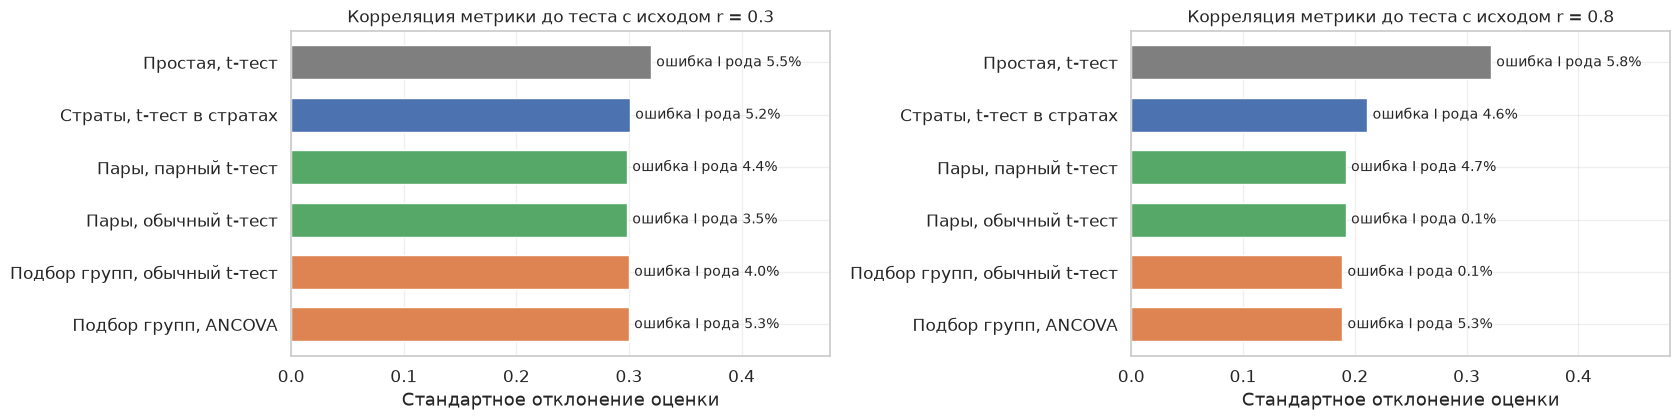

,SD оценки,Ошибка I рода
"Простая, t-тест",0.322,0.058
"Страты, t-тест в стратах",0.211,0.046
"Пары, парный t-тест",0.192,0.047
"Пары, обычный t-тест",0.192,0.001
"Подбор групп, обычный t-тест",0.188,0.001
"Подбор групп, ANCOVA",0.188,0.053


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.4))
design_tables = {}
for ax, r in zip(axes, [0.3, 0.8]):
    design_tables[r] = compare_designs(r)
    plot_designs(ax, design_tables[r], r)
plt.tight_layout()
plt.show()
design_tables[0.8].round(3)

При сильной связи ($r = 0.8$) стратификация снижает SD с 0.32 до 0.21, а пары и подбор групп до 0.19. Это почти вдвое, и такой же результат дал бы рост числа кластеров почти втрое. При слабой связи ($r = 0.3$) выигрыш мал, но и вреда нет.

Обратите внимание на строки с обычным t-тестом. Пары и подбор групп с ним дают ошибку первого рода 0.1% вместо 5%. Это не достижение, а признак несоответствия: тест считает дисперсию как при простой рандомизации и поэтому впустую теряет мощность. Парный t-тест и ANCOVA возвращают 5%.

Этот эффект виден и на практике. В [кейсе Avito](https://habr.com/ru/companies/avito/articles/1040162/) с оценкой времени обработки обращений единицей рандомизации был специалист поддержки, а не обращение. Их 20–150 на группу, то есть это кластерный тест с малым числом кластеров. Авторы собирали группы генетическим алгоритмом с балансом по профилю сотрудника. В A/A доля ложных срабатываний упала с 5.8–6.5% до 1% и ниже. Авторы воспринимают это как улучшение и не разбирают теорию. Наша симуляция добавляет важное уточнение: заниженная ошибка означает, что обычный тест перестал соответствовать дизайну. Лучше перейти к критерию, который её учитывает: добавить метрику до теста как ковариату (там же использован CUPED) либо считать p-value перестановками внутри допустимых разбиений.

**Вопрос.** В городе 14 районов очень разного размера, рандомизировали районы. Аналитик строит регрессию по пользователям в `statsmodels` с кластеризованными стандартными ошибками по району, `cov_type="cluster"`. Это уже честный тест?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Не вполне: кластеризованные ошибки правильно учитывают зависимость, но опираются на асимптотику по числу кластеров, а 14 неравных районов — это мало. В симуляции ниже на 14 кластерах сильно разного размера поправка CR1 с нормальным приближением даёт около 17% ложных срабатываний вместо 5%. Надёжнее wild cluster bootstrap, агрегация до районов, CR2 с поправкой степеней свободы или рандомизационный вывод. А перед запуском стоит прогнать выбранный метод на A/A по истории: это единственный способ узнать его настоящую ошибку на ваших кластерах.

</details>

## Как анализировать

Есть две стратегии: свернуть данные до кластеров или оставить пользователей и исправить дисперсию.

**1. Агрегация до кластеров.** Считаем метрику в каждом кластере и применяем t-тест к $k$ значениям. Это просто и честно: единица анализа совпадает с единицей рандомизации. При равных размерах оценка совпадает с регрессией, а интервал почти совпадает с CR2. При неравных размерах такой тест оценивает эффект на кластер, а не на пользователя.

**2. Кластеризованные стандартные ошибки (CRSE).** Для регрессии $Y_{ij} = \alpha + \tau T_j + e_{ij}$ оценка дисперсии

$$
\widehat{\text{Var}}(\hat{\beta}) = (X'X)^{-1} \bigg(\sum_{j=1}^{k} X_j' \hat{e}_j \hat{e}_j' X_j\bigg) (X'X)^{-1}
$$

разрешает любые зависимости внутри кластера. Для бинарного $T$ она равна дельта-методу из предыдущего раздела (вариант CR0). Варианты отличаются поправками:

* **CR1** умножает дисперсию на $\frac{k}{k-1}\frac{N-1}{N-2}$;
* **CR2** (Белл и Маккаффри) поправляет остатки на рычаг кластера. В нашем случае $\hat{\psi}_j$ делится на $\sqrt{1 - n_j/N_t}$, и степени свободы считаются по Саттертуэйту.

Эти оценки опираются на асимптотику по **числу кластеров**, поэтому при малом $k$ занижают дисперсию. [Камерон и Миллер (2015)](https://jhr.uwpress.org/content/50/2/317) отмечают, что твёрдой границы нет: «мало» может значить и меньше 20, и меньше 50 кластеров. Дисбаланс размеров ухудшает ситуацию.

**3. Wild cluster bootstrap.** Здесь мы фиксируем назначение и случайно меняем знак остатков кластера целиком: $y^*_j = \tilde{y}_j + w_j \tilde{e}_j$, $w_j = \pm 1$, где прогноз и остатки считаются при верной нулевой гипотезе. [Обзор Макиннона и соавторов](https://arxiv.org/pdf/2205.03285) рекомендует этот метод как основной при малом числе кластеров. Он сохраняет структуру внутри кластера.

**4. Рандомизационный вывод (permutation).** Перебираем назначения так же, как делали при запуске, и смотрим, где наша статистика. P-value равно $(1 + \#\{|t^*| \geq |t|\}) / (B + 1)$. Метод опирается только на дизайн, а его гарантия по ошибке первого рода точная, если воздействия нет ни у кого.

Почему кластеризовать вообще нужно? [Абади, Эйти, Имбенс и Вулдридж](https://arxiv.org/abs/1710.02926) объясняют: кластеризация — это вопрос дизайна. Ошибки надо кластеризовать на уровне, на котором назначалось воздействие. Корреляция сама по себе не повод: в обычном A/B с рандомизацией по пользователям не надо кластеризовать по городам, даже если исходы внутри города похожи.

Сначала убедимся, что дельта-метод — это CR0: сверим с `statsmodels`.

In [14]:
def cluster_statistics(means, sizes, treated):
    """Считает оценку и дисперсии CR0, CR1, CR2 для отношения сумм по матрице симуляций."""
    n1, n0 = (sizes * treated).sum(axis=-1, keepdims=True), (sizes * ~treated).sum(axis=-1, keepdims=True)
    r1, r0 = (means * sizes * treated).sum(axis=-1, keepdims=True) / n1, (means * sizes * ~treated).sum(axis=-1, keepdims=True) / n0
    estimate = (r1 - r0)[..., 0]
    psi = sizes * (means - np.where(treated, r1, r0))
    share = np.where(treated, n1, n0)
    v1 = (psi ** 2 * treated).sum(axis=-1) / n1[..., 0] ** 2
    v0 = (psi ** 2 * ~treated).sum(axis=-1) / n0[..., 0] ** 2
    cr2_t = (psi ** 2 / (1 - sizes / share) * treated).sum(axis=-1) / n1[..., 0] ** 2
    cr2_c = (psi ** 2 / (1 - sizes / share) * ~treated).sum(axis=-1) / n0[..., 0] ** 2
    return estimate, v1 + v0, cr2_t, cr2_c


check = np.random.default_rng(7)
k_check = 12
sizes_check = check.integers(20, 200, k_check)
arm = np.arange(k_check) % 2 == 0
frame = pd.DataFrame({'cluster': np.repeat(np.arange(k_check), sizes_check), 'treated': np.repeat(arm.astype(int), sizes_check)})
frame['y'] = 0.3 * frame['treated'] + np.repeat(check.normal(0, 0.3, k_check), sizes_check) + check.normal(0, 1, len(frame))

grouped = frame.groupby('cluster')['y'].mean().to_numpy()
estimate, cr0, _, _ = cluster_statistics(grouped, sizes_check.astype(float), arm)
fit = smf.ols('y ~ treated', frame).fit(cov_type='cluster', cov_kwds={'groups': frame['cluster'], 'use_correction': False})
print(f'Оценка: наша {float(estimate):.5f}, statsmodels {fit.params["treated"]:.5f}')
print(f'SE:     наша {np.sqrt(float(cr0)):.5f}, statsmodels {fit.bse["treated"]:.5f}')

Оценка: наша 0.21486, statsmodels 0.21486
SE:     наша 0.12080, statsmodels 0.12080


Оценка и стандартная ошибка совпали до пятого знака: дельта-метод для разницы отношений и CR0 — это одно и то же.

Теперь главный график этой части: какая ошибка первого рода у каждого метода в зависимости от числа кластеров. Сравним равные размеры кластеров и сильно разные ($CV \approx 1$), ICC 0.05.

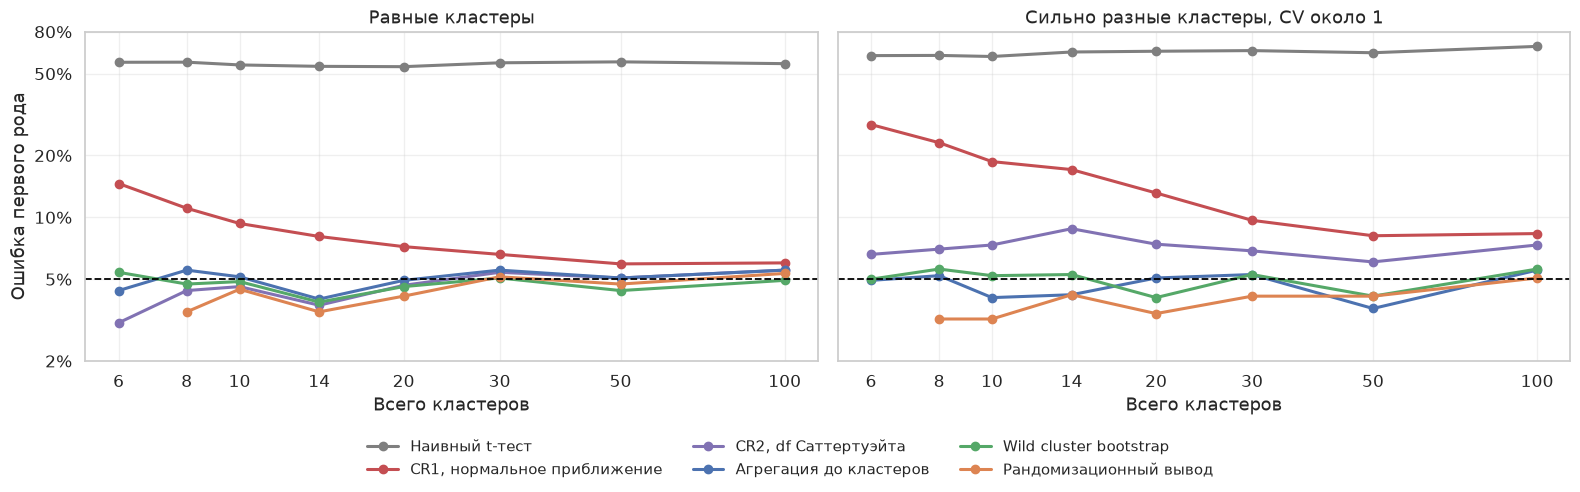

,Наивный t-тест,"CR1, нормальное приближение","CR2, df Саттертуэйта",Агрегация до кластеров,Wild cluster bootstrap,Рандомизационный вывод
6,0.612,0.283,0.066,0.049,0.050,0.000
8,0.613,0.231,0.070,0.052,0.056,0.032
10,0.606,0.187,0.073,0.041,0.052,0.032
14,0.637,0.171,0.088,0.042,0.053,0.042
20,0.643,0.131,0.074,0.051,0.041,0.034
30,0.647,0.097,0.069,0.053,0.053,0.041
50,0.632,0.081,0.061,0.036,0.041,0.041
100,0.679,0.083,0.073,0.055,0.056,0.051


In [15]:
def sizes_for(k, unequal, base=200):
    if not unequal:
        return np.full(k, float(base))
    quantiles = st.norm.ppf((np.arange(k) + 0.5) / k)
    return np.maximum(np.exp(quantiles * 0.95 + np.log(base) - 0.45), 5).round()


def error_rates(k, unequal, effect=0.0, icc=0.05, reps=1500, boot=199, seed=8):
    """Считает долю отклонений H0 разными методами при заданном эффекте."""
    local = np.random.default_rng(seed + k + int(unequal))
    sizes = sizes_for(k, unequal)
    means = simulate_cluster_means(sizes, icc, reps, local)
    treated = random_assignment(reps, k, local)
    means = means + effect * treated
    G = k // 2

    estimate, cr0, cr2_t, cr2_c = cluster_statistics(means, sizes, treated)
    N = sizes.sum()
    cr1 = cr0 * k / (k - 1) * (N - 1) / (N - 2)
    t_cr1 = estimate / np.sqrt(cr1)
    cr2 = cr2_t + cr2_c
    df = cr2 ** 2 / (cr2_t ** 2 / (G - 1) + cr2_c ** 2 / (G - 1))

    naive_se = np.sqrt(4 / sizes.sum())
    cluster_t = st.ttest_ind(np.where(treated, means, np.nan), np.where(treated, np.nan, means), axis=1, nan_policy='omit').pvalue
    cluster_t = np.asarray(cluster_t, dtype=float)

    rejected = {'Наивный t-тест': np.abs(estimate / naive_se) > 1.96,
                'CR1, нормальное приближение': np.abs(t_cr1) > 1.96,
                'CR2, df Саттертуэйта': 2 * st.t.sf(np.abs(estimate) / np.sqrt(cr2), df) < 0.05,
                'Агрегация до кластеров': cluster_t < 0.05}

    wild, permutation = np.zeros(reps, bool), np.zeros(reps, bool)
    for rep in range(reps):
        y, arm = means[rep], treated[rep]
        pooled = (y * sizes).sum() / N
        signs = local.choice([-1.0, 1.0], (boot, k))
        star = pooled + signs * (y - pooled)
        boot_est, boot_var, _, _ = cluster_statistics(star, sizes, arm[None, :])
        wild[rep] = (1 + np.sum(np.abs(boot_est / np.sqrt(boot_var)) >= abs(estimate[rep] / np.sqrt(cr0[rep])))) / (boot + 1) < 0.05

        options = np.argsort(local.random((boot, k)), axis=1) < G
        perm_est, perm_var, _, _ = cluster_statistics(np.broadcast_to(y, (boot, k)), sizes, options)
        permutation[rep] = (1 + np.sum(np.abs(perm_est / np.sqrt(perm_var)) >= abs(estimate[rep] / np.sqrt(cr0[rep])))) / (boot + 1) < 0.05

    rejected['Wild cluster bootstrap'] = wild
    rejected['Рандомизационный вывод'] = permutation
    return {name: value.mean() for name, value in rejected.items()}


cluster_counts = [6, 8, 10, 14, 20, 30, 50, 100]
false_positive = {unequal: pd.DataFrame({k: error_rates(k, unequal) for k in cluster_counts}).T for unequal in [False, True]}

METHOD_COLORS = {'Наивный t-тест': GRAY, 'CR1, нормальное приближение': RED, 'CR2, df Саттертуэйта': PURPLE,
                 'Агрегация до кластеров': BLUE, 'Wild cluster bootstrap': GREEN, 'Рандомизационный вывод': ORANGE}

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, unequal, title in zip(axes, [False, True], ['Равные кластеры', 'Сильно разные кластеры, CV около 1']):
    table = false_positive[unequal]
    for method, color in METHOD_COLORS.items():
        ax.plot(table.index, table[method].replace(0, np.nan), 'o-', color=color, lw=2.2, label=method)
    ax.axhline(0.05, color='black', ls='--', lw=1.3)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.minorticks_off()
    ax.set_xticks(cluster_counts, cluster_counts)
    ax.set_yticks([0.02, 0.05, 0.1, 0.2, 0.5, 0.8], ['2%', '5%', '10%', '20%', '50%', '80%'])
    ax.set_xlabel('Всего кластеров')
    ax.set_title(title)
axes[0].set_ylabel('Ошибка первого рода')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False, fontsize=11)
plt.tight_layout(rect=(0, 0.11, 1, 1))
plt.show()
false_positive[True].round(3)

* Наивный t-тест ошибается в 55–68% случаев и при равных, и при разных кластерах, причём число кластеров ему не помогает.
* CR1 с нормальным приближением заметно занижает дисперсию при малом $k$: при разных размерах 28% ложных срабатываний на 6 кластерах, 13% на 20 и всё ещё 8% на 100. Выходит, что «100 кластеров достаточно» неверно при сильном дисбалансе.
* CR2 с поправкой степеней свободы гораздо лучше: 6.6–8.8%. Здесь используется упрощённая формула степеней свободы.
* Агрегация и wild bootstrap держат уровень около 5%.
* Рандомизационный вывод слегка консервативен. На 6 кластерах его нельзя применить: существует всего 20 разбиений, поэтому минимальное двустороннее p-value равно 0.1, и значимость недостижима. Это важное практическое ограничение: при малом числе кластеров заранее посчитайте, сколько возможно разбиений.

Посмотрим на мощность тех методов, которые держат уровень, при эффекте 0.15 стандартного отклонения.

In [16]:
power_counts = [10, 20, 50, 100]
power = pd.DataFrame({k: error_rates(k, True, effect=0.15, reps=800) for k in power_counts}).T[['CR2, df Саттертуэйта', 'Агрегация до кластеров', 'Wild cluster bootstrap', 'Рандомизационный вывод']]
power.rename_axis('Кластеров').round(3)

,"CR2, df Саттертуэйта",Агрегация до кластеров,Wild cluster bootstrap,Рандомизационный вывод
Кластеров,,,,
10,0.184,0.149,0.150,0.089
20,0.258,0.264,0.192,0.184
50,0.395,0.542,0.361,0.350
100,0.648,0.851,0.601,0.605


**Вопрос.** Тест на 20 кластерах показал значимый эффект 0.3 стандартного отклонения при честной мощности 20–25% для эффекта 0.15. Посчитано корректно, wild bootstrap. Продакт радуется: эффект вдвое больше, чем мы надеялись. Что вы скажете, вспоминая встречу 2?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Скорее всего, эффект завышен: при мощности 20–25% значимыми становятся в основном оценки, которым повезло с шумом. Это ошибка M типа из встречи 2: чем ниже мощность, тем сильнее значимая оценка преувеличивает настоящий эффект, и двукратное завышение здесь вполне типично. Кластерные тесты почти всегда маломощны, потому что мощность задают кластеры, а не пользователи. А наивный t-тест по пользователям здесь вообще ничего не доказывает: в A/A он ошибается больше чем в 60% случаев, так что его «значимость» добавила бы ложную уверенность и в знаке, и в размере эффекта. Честный отчёт — интервал, а не точка, и, если решение дорогое, повторный тест или пересчёт с консервативным ожиданием эффекта.

</details>

Мощность низка при любом методе: при 20 кластерах 18–26%, при 100 только 60–85%. Агрегация здесь мощнее, потому что каждый кластер весит одинаково, а большие кластеры не забирают вес. Но здесь эффект одинаков во всех кластерах, и она оценивает эффект на кластер. Если эффект зависит от размера, это другая величина, поэтому выбирать метод только по мощности нельзя.

Для снижения дисперсии работает CUPED на уровне кластера: добавляем в регрессию значение метрики до теста, посчитанное по кластеру. В работе Meta такая корректировка снизила стандартные ошибки более чем на 30%. Здесь выигрыш может быть больше, чем в обычном тесте, потому что среднее кластера стабильно во времени: шум пользователей усредняется, а $u_j$ остаётся.

## Сценарий: готовые группы

Школы, магазины, отделения банка, классы. Кластеры заданы, граф не нужен. Возьмём данные о мышлении роста (learning mindset): 10 391 ученик из 76 школ. Данные смоделированы Эйти и Вейджером по настоящему исследованию, но структура кластеров реалистична. Оценим ICC и посмотрим, что бы было, если бы семинар назначался школам целиком.

ICC оцениваем дисперсионным анализом:

$$
\hat{\rho} = \frac{MSB - MSW}{MSB + (m_0 - 1) MSW}, \qquad m_0 = \frac{N - \sum n_j^2 / N}{k - 1}
$$

где $MSB$ и $MSW$ — средние квадраты между и внутри кластеров.

Школ: 76, средний размер 137, CV размеров 0.73
ICC = 0.088, эффект дизайна = 19.3, эффективных учеников из 10391: 539
Корреляция среднего балла школы с показателем до теста: 0.05


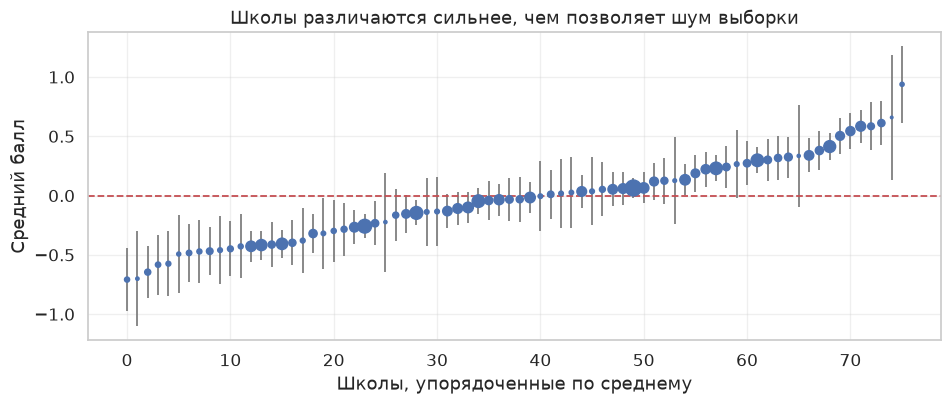

In [17]:
schools = pd.read_csv(DATA + 'learning_mindset.csv')
outcome_school = schools.groupby('schoolid').agg(n=('achievement_score', 'size'), y=('achievement_score', 'mean'), pre=('school_achievement', 'first'))


def anova_icc(data, cluster, value):
    groups = data.groupby(cluster)[value]
    sizes, means = groups.size(), groups.mean()
    N, k = sizes.sum(), len(sizes)
    grand = data[value].mean()
    msb = (sizes * (means - grand) ** 2).sum() / (k - 1)
    msw = ((data[value] - groups.transform('mean')) ** 2).sum() / (N - k)
    m0 = (N - (sizes ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (m0 - 1) * msw)


icc_school = anova_icc(schools, 'schoolid', 'achievement_score')
sizes_school = outcome_school['n'].to_numpy(float)
cv_school = sizes_school.std() / sizes_school.mean()
de_school = design_effect(sizes_school.mean(), icc_school, cv_school)
print(f'Школ: {len(sizes_school)}, средний размер {sizes_school.mean():.0f}, CV размеров {cv_school:.2f}')
print(f'ICC = {icc_school:.3f}, эффект дизайна = {de_school:.1f}, эффективных учеников из {len(schools)}: {len(schools) / de_school:.0f}')
print(f"Корреляция среднего балла школы с показателем до теста: {outcome_school['y'].corr(outcome_school['pre']):.2f}")

order = outcome_school.sort_values('y')
fig, ax = plt.subplots(figsize=(11, 4))
ax.vlines(np.arange(len(order)), order['y'] - 1.96 * schools['achievement_score'].std() / np.sqrt(order['n']), order['y'] + 1.96 * schools['achievement_score'].std() / np.sqrt(order['n']), color=GRAY, lw=1.3)
ax.scatter(np.arange(len(order)), order['y'], color=BLUE, s=order['n'] / 4, zorder=3)
ax.axhline(schools['achievement_score'].mean(), color=RED, ls='--', lw=1.3)
ax.set_xlabel('Школы, упорядоченные по среднему')
ax.set_ylabel('Средний балл')
ax.set_title('Школы различаются сильнее, чем позволяет шум выборки');

Проведём **A/A на этих данных**: многократно случайно делим школы пополам, не применяя воздействия. Заодно добавим искусственный эффект и оценим мощность. Это ровно тот пайплайн, который [X5](https://habr.com/ru/companies/X5Tech/articles/466349/) использует для магазинов: подбор групп, проверка равенства в предпилотном периоде, добавление искусственного эффекта и браковка метода, если ошибки выходят за порог. Сравним простое разбиение и пары по средней успеваемости школы до теста.

In [18]:
def school_aa(paired, effect=0.0, reps=3000, seed=9):
    """Делит школы на группы и считает долю значимых результатов."""
    local = np.random.default_rng(seed)
    ordered = outcome_school.sort_values('pre')
    y, n = ordered['y'].to_numpy(), ordered['n'].to_numpy(float)
    k = len(y) - len(y) % 2
    y, n = y[:k], n[:k]
    naive_se = schools['achievement_score'].std() * np.sqrt(1 / (n.sum() / 2) * 2)
    estimates, cluster_p, paired_p, naive = [], [], [], []
    for _ in range(reps):
        if paired:
            flip = local.random(k // 2) < 0.5
            arm = np.zeros(k, bool)
            arm[np.arange(0, k, 2) + flip] = True
        else:
            arm = local.permutation(np.arange(k) < k // 2)
        outcome = y + effect * arm
        ratio = (outcome * n * arm).sum() / (n * arm).sum() - (outcome * n * ~arm).sum() / (n * ~arm).sum()
        estimates.append(ratio)
        naive.append(abs(ratio / naive_se) > 1.96)
        cluster_p.append(st.ttest_ind(outcome[arm], outcome[~arm]).pvalue < 0.05)
        if paired:
            first, second = outcome[0::2], outcome[1::2]
            sign = np.where(arm[0::2], 1, -1)
            paired_p.append(st.ttest_1samp(sign * (first - second), 0).pvalue < 0.05)
    result = {'SD оценки': np.std(estimates), 'Наивный тест': np.mean(naive), 'Тест по школам': np.mean(cluster_p)}
    if paired:
        result['Парный тест'] = np.mean(paired_p)
    return result


pd.DataFrame({'Простое разбиение, A/A': school_aa(False), 'Пары, A/A': school_aa(True),
              'Простое разбиение, эффект 0.2': school_aa(False, 0.2), 'Пары, эффект 0.2': school_aa(True, 0.2)}).T.round(3)

,SD оценки,Наивный тест,Тест по школам,Парный тест
"Простое разбиение, A/A",0.078,0.626,0.052,NaN
"Пары, A/A",0.076,0.632,0.047,0.049
"Простое разбиение, эффект 0.2",0.078,0.981,0.669,NaN
"Пары, эффект 0.2",0.076,0.984,0.673,0.660


ICC равен 0.088, а эффект дизайна 19.3: из 10 391 ученика эффективных остаётся около 540. На A/A наивный тест ошибается в 63% случаев, а тест по школам в 5%. При эффекте 0.2 у наивного теста «мощность» 98%, но это мнимая цифра: честная мощность 67%.

Пары здесь почти не помогли: SD 0.076 против 0.078. Причина видна из вывода выше: показатель школы до теста слабо связан со средним баллом, корреляция равна всего 0.05. Паровать надо по признаку, который реально предсказывает исход. В магазинах им обычно становится сама метрика в прошлом периоде, поэтому X5 подбирает пары по её истории и трендам.

## Чек-лист запуска кластерного теста

**До теста**

1. Определите причину кластеризации и какой уровень реально разрывает зависимость.
2. Определите оцениваемую величину: эффект на пользователя, на кластер или глобальный эффект.
3. Оцените ICC и эффект дизайна на истории, посчитайте MDE по числу кластеров.
4. Выберите схему рандомизации: стратификацию или пары, где это возможно.
5. Зафиксируйте метод анализа и проверьте его на A/A и искусственном эффекте.

**Во время теста**

6. Следите за утечками: перемещения между кластерами, изменение состава.
7. Состав кластера определяйте заранее. Если воздействие меняет то, кто попадает в кластер, возникает смещение отбора.

**Анализ**

8. Анализируйте на уровне назначения и учитывайте схему: пары, страты, подбор.
9. При малом числе кластеров используйте рандомизационный вывод, wild bootstrap или агрегацию.
10. Используйте метрику до теста. Для геотестов это почти обязательно.
11. Проверьте остаточную интерференцию, если есть основания.

## Типичные ошибки

* Назначить кластерам, а считать t-тест по пользователям.
* Планировать мощность по числу пользователей.
* Считать кластером то, что удобно, а не то, что разрывает зависимость.
* Оптимизировать разбиение на результат самого теста.
* Подбирать группы, а анализировать как при простой рандомизации.
* Смотреть на A/A только по ошибке первого рода: занижение тоже сигнал о несоответствии.
* Считать, что кластеры устранили всю интерференцию.

## Когда кластеров мало, а ресурс общий: switchback

**Вопрос.** В тесте новой цены такси тест показал +10 п.п. к поездкам на пассажира, но водителей в часы пик не хватает. Коллега предлагает продлить тест вдвое, «чтобы оценка стала надёжнее». Поможет?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет: здесь проблема в смещении, а не в шуме, и рост выборки сужает интервал вокруг неверного числа. Тестовые пассажиры забирают водителей у контрольных, поэтому контроль становится хуже, чем был бы без теста, и разница групп больше эффекта полного внедрения. Если предложение ограничено, настоящий эффект может быть даже нулевым: новых поездок не появится, они лишь перераспределятся. Лечится это дизайном: всё, что делит общий ресурс, должно получать одно воздействие, то есть рандомизировать нужно зону и время, а не пассажира.

</details>

В кластерной части главной бедой было малое число кластеров. В доставке и такси всё ещё хуже: город часто один, курьеры и водители общие для всех пользователей, и деление на районы не разрывает зависимость полностью. Выход — сделать единицей рандомизации пару «зона–время»: весь район на несколько часов уходит в тест, затем случайно переключается. Единиц становится больше за счёт времени, но появляются новые проблемы: перенос эффекта между окнами и корреляция соседних часов.

### Критика классического A/B-тестирования

В основе валидности классического A/B-тестирования лежит условие **Stable Unit Treatment Value Assumption (SUTVA)**. Оно состоит из двух частей: исход единицы зависит только от её собственного воздействия, а у воздействия нет скрытых разных версий. Формально $Y_i(Z_1, \dots, Z_n) = Y_i(Z_i)$. Иными словами, изменение затрагивает только ту группу, к которой применено, и не влияет на единицы других групп.

Обратите внимание: SUTVA — это условие на **потенциальные исходы**, а не статистическая независимость наблюдений. Нарушение SUTVA называют **сетевым эффектом** или **интерференцией**, и главная проблема здесь — **смещение** оценки эффекта. Пример мы посмотрим ниже.

Есть и вторая, отдельная проблема: когда мы боремся с интерференцией укрупнением единицы рандомизации, наблюдения внутри единицы получают одно и то же воздействие и начинают коррелировать. Это **раздувает дисперсию**. Покажем её источник с помощью **атомов Хорвица–Томпсона (HT)**.

Атом HT для единицы $i$ определяется как:

$$
A_i := \left( \frac{Z_i}{q_i} - \frac{1 - Z_i}{1 - q_i} \right) Y_i
$$

где:
- $Z_i$ — индикатор назначения в тестовую группу;
- $q_i := \Pr(Z_i = 1)$ — вероятность назначения в тест;
- $Y_i := Z_i \, Y_i(1) + (1 - Z_i) \, Y_i(0)$ — наблюдаемый исход.

Потенциальные исходы считаем фиксированными, вся случайность заключена в $Z_i$. Тогда атом — это несмещённая оценка индивидуального эффекта:

$$
\mathbb{E}[A_i] = Y_i(1) - Y_i(0) =: \tau_i
$$

Среднее атомов — это оценка среднего эффекта, а дисперсия этой оценки складывается из дисперсий атомов и ковариаций между ними. Рассмотрим две единицы $s$ и $t$:

* **Независимая рандомизация.** Если $Z_s$ и $Z_t$ независимы, то $\mathbb{E}[A_s A_t] = \tau_s \tau_t$ и $\operatorname{Cov}(A_s, A_t) = 0$.

* **Общая единица рандомизации.** Если обе единицы попали в один ключ рандомизации (одну зону в один интервал), то $Z_s = Z_t = Z$, $\Pr(Z = 1) = q$. Смешанные слагаемые содержат $Z(1-Z) = 0$ и исчезают:

$$
\mathbb{E}[A_s A_t] = \frac{Y_s(1) Y_t(1)}{q} + \frac{Y_s(0) Y_t(0)}{1 - q}
$$

Вычитая $\tau_s \tau_t$, получаем:

$$
\operatorname{Cov}(A_s, A_t) = \frac{1-q}{q} Y_s(1) Y_t(1) + \frac{q}{1-q} Y_s(0) Y_t(0) + Y_s(1) Y_t(0) + Y_s(0) Y_t(1)
$$

При $q = 1/2$ это выражение равно $\big(Y_s(1) + Y_s(0)\big)\big(Y_t(1) + Y_t(0)\big)$. Для положительных метрик оно строго положительно.

**Итог:** единицы с общим ключом рандомизации положительно коррелируют, поэтому анализ нужно вести на уровне ключа, а не отдельного наблюдения. Иначе стандартная ошибка будет занижена.

**Примеры искажений**

  *   **Модель взаимодействия водитель-пассажир в такси:**
        В логистических сервисах, таких как такси или доставка еды, водители (или курьеры) являются **общим ресурсом** для всех пассажиров (или клиентов) в определенной географической зоне.
        Рассмотрим пример, где Миша и Коля, живущие в соседних домах, заказывают такси утром примерно в одно время. Коля находится в контрольной группе (старый алгоритм ценообразования), а Миша — в тестовой (новый алгоритм, снизивший цену на 5%).
        Миша, видя более низкую цену, быстрее принимает решение о заказе, тем самым **"отнимая" водителя у Коли**. В результате Коля остаётся без машины и, возможно, вообще отказывается от поездки, поскольку свободных машин в округе больше нет.
        В этой ситуации **конверсия Коли занижена из-за Миши**: изменённые условия повлияли не только на решение Миши, но и на Колю. Это прямое нарушение SUTVA, поскольку результат Коли был загрязнён воздействием, применённым к Мише через **общий пул водителей**. Разница между группами получается больше реального эффекта: тест выглядит лучше частично потому, что контроль стал хуже.

  *   **Эффект перераспределения спроса в динамическом ценообразовании:**
        В двусторонних и трёхсторонних маркетплейсах, таких как Uber, Lyft или DoorDash, динамическое ценообразование (например, surge pricing) используется для балансировки спроса и предложения.
        Если на тестовой территории вводится новая система ценообразования (например, повышенные тарифы для снижения спроса в часы пик), это может привести к **перераспределению спроса**. Клиенты, столкнувшись с повышенными ценами, могут принять решение либо **отказаться от поездки**, либо **переместиться в соседнюю зону**, где цены остались прежними.
        Этот "перелив" спроса означает, что контрольная группа, находящаяся в соседней зоне, **косвенно затронута экспериментом** в тестовой зоне. В результате KPI контрольной группы будут «загрязнены» эффектом перелива из тестовой группы. Это искажает истинную реакцию потребителей и приводит к **смещенной оценке эффективности** нового алгоритма. Аналогичные проблемы возникают при тестировании алгоритмов распределения заказов или систем стимулирования водителей.

**Последствия использования обычного A/B-тестирования в условиях сетевого эффекта**:

*   **Искажение и смещение результатов**:

Поскольку группы влияют друг на друга, разность между ними не равна эффекту от полного внедрения. Это приводит к **некорректным оценкам причинно-следственных связей**. Фактический эффект может быть сильно переоценен или недооценен, что приведет к неоптимальным или даже вредным решениям о развертывании функций.
*   **Неверная оценка статистической значимости**:

Положительная корреляция наблюдений внутри единицы рандомизации, если её не учесть, приводит к **недооценке стандартных ошибок** и, как следствие, **переоценке статистической значимости**. Это означает, что вы можете объявить эффект "статистически значимым", когда на самом деле это произошло случайно, увеличивая риск **ошибки первого рода (False Positive Rate - FPR)**. FPR перестает контролироваться пороговым значением p-value, что делает выводы из теста ненадежными.
*   **Снижение мощности эксперимента**:

Если для борьбы с сетевым эффектом перейти к более крупным «юнитам» (например, гео-час), количество таких юнитов может оказаться небольшим, что **снижает статистическую мощность теста**. В результате вы можете не обнаружить истинный эффект, даже если он присутствует (увеличивается риск ошибки второго рода), или вам потребуется значительно удлинять эксперимент, что может быть неэффективно или невозможно.
*   **Затруднение интерпретации и выводов**:

Когда сетевые эффекты присутствуют, становится крайне сложно однозначно интерпретировать результаты. Неясно, является ли наблюдаемый эффект прямым результатом изменения или косвенным следствием взаимодействия групп. Это затрудняет формулирование четких выводов и рекомендаций для бизнеса.

**Как интерференция искажает оценку**

Смоделируем зону в течение часа: есть пул водителей и пассажиры. Тестовая цена ниже, поэтому пассажиры из теста охотнее делают заказ: 72% против 60% в контроле. Заказы конкурируют за одних и тех же водителей.

Сравним три величины:

* **Настоящий эффект** — разница в поездках на пассажира при полном внедрении теста и при полном контроле;
* **A/B-тест** — пользователи одной зоны в один час случайно делятся пополам;
* **Switchback** — весь час зоны случайно уходит в тест или контроль.

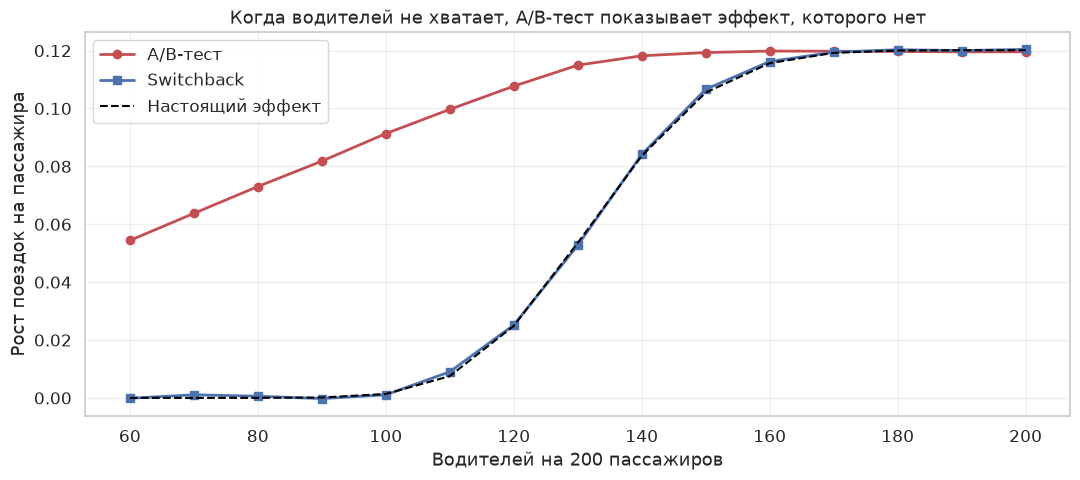

,Настоящий эффект,A/B-тест,Switchback
80,0.000,0.073,0.001
120,0.025,0.108,0.025
160,0.116,0.120,0.116
200,0.120,0.120,0.120


In [19]:
def market_hour(n_riders: np.ndarray, n_test: np.ndarray, supply: np.ndarray, rng: np.random.Generator,
                p_control: float = 0.60, p_test: float = 0.72) -> tuple:
    """Разыгрывает час зоны: заказы групп конкурируют за водителей, поездки делятся случайно."""
    demand_test = rng.binomial(n_test, p_test)
    demand_control = rng.binomial(n_riders - n_test, p_control)
    demand = demand_test + demand_control
    rides = np.minimum(demand, supply)
    rides_test = rng.hypergeometric(demand_test, demand_control, rides)
    return rides_test, rides - rides_test


def interference_experiment(supply_level: int, n_hours: int = 20_000, n_riders: int = 200, seed: int = 1) -> dict:
    """Сравнивает настоящий эффект, A/B-тест и switchback при заданном числе водителей."""
    rng = np.random.default_rng(seed)
    riders = np.full(n_hours, n_riders)
    supply = rng.poisson(supply_level, n_hours)

    all_test, _ = market_hour(riders, riders, supply, rng)
    _, all_control = market_hour(riders, np.zeros(n_hours, dtype=int), supply, rng)
    true_effect = (all_test.mean() - all_control.mean()) / n_riders

    half = np.full(n_hours, n_riders // 2)
    rides_test, rides_control = market_hour(riders, half, supply, rng)
    ab_effect = (rides_test.mean() - rides_control.mean()) / half[0]

    switch = rng.integers(0, 2, n_hours).astype(bool)
    rides_t, rides_c = market_hour(riders, switch * n_riders, supply, rng)
    switchback_effect = ((rides_t + rides_c)[switch].mean() - (rides_t + rides_c)[~switch].mean()) / n_riders
    return {'Настоящий эффект': true_effect, 'A/B-тест': ab_effect, 'Switchback': switchback_effect}


supply_grid = np.arange(60, 201, 10)
curves = pd.DataFrame([interference_experiment(level) for level in supply_grid], index=supply_grid)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(curves.index, curves['A/B-тест'], color=RED, marker='o', linewidth=2, label='A/B-тест')
ax.plot(curves.index, curves['Switchback'], color=BLUE, marker='s', linewidth=2, label='Switchback')
ax.plot(curves.index, curves['Настоящий эффект'], color='black', linestyle='--', linewidth=1.5, label='Настоящий эффект')
ax.set(xlabel='Водителей на 200 пассажиров', ylabel='Рост поездок на пассажира', title='Когда водителей не хватает, A/B-тест показывает эффект, которого нет')
ax.legend()
plt.tight_layout()
plt.show()

curves.loc[[80, 120, 160, 200]].round(3)

Когда водителей мало, все заказы упираются в предложение. При 80 водителях на 200 пассажиров настоящий эффект равен нулю: снижение цены не добавляет ни одной поездки. Но A/B-тест показывает рост на 7.3 процентных пункта, потому что тест просто забирает водителей у контроля. При 120 водителях настоящий эффект 2.5 п.п., а A/B показывает 10.8 п.п. Switchback в обоих случаях попадает в настоящий эффект. Когда водителей с запасом (160 и больше), интерференция исчезает, и оба метода совпадают.

Это главный аргумент в пользу switchback: проблема A/B-теста здесь не в шуме, а в систематическом смещении, которое не лечится ростом выборки.

**Попробуйте сами.** Эта ячейка интерактивная: задайте число водителей и сравните оценки. Статичная версия показана выше.

In [20]:
def interference_demo(supply: int = 100) -> None:
    """Сравнивает оценки эффекта при выбранном числе водителей."""
    result = pd.Series(interference_experiment(supply))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.barh(result.index, result.values, color=[GRAY, RED, BLUE], height=0.6)
    for position, value in enumerate(result.values):
        ax.text(value, position, f' {value:.3f}', va='center')
    ax.set(xlim=(min(result.min(), 0) - 0.02, max(result.max(), 0.12) * 1.25), xlabel='Рост поездок на пассажира', title=f'{supply} водителей на 200 пассажиров')
    plt.tight_layout()
    plt.show()


interact(interference_demo, supply=IntSlider(value=100, min=60, max=200, step=10, description='Водителей'));

interactive(children=(IntSlider(value=100, description='Водителей', max=200, min=60, step=10), Output()), _dom…

Таким образом, в сложных динамических средах классическое A/B-тестирование оказывается несостоятельным и требует других методологий, таких как switchback-тестирование.

## Концепция switchback-тестирования

**Switchback-тестирование** — это фреймворк для проведения экспериментов, который циклически чередует применения различных «трактовок» (тестовых или контрольных условий) во времени для оценки их эффективности. В отличие от традиционных A/B-тестов, где трафик делится на независимые группы пользователей одновременно, Switchback-тесты основаны на **рандомизации по временным слотам** и/или **географическим единицам** (кластерам).

Формально, в Switchback-эксперименте мы делим среду тестирования на **дискретные единицы**, которые затем случайным образом назначаются в контрольную или тестовую группу в определённые периоды времени. В контексте Switchback-тестирования, **единицей (Unit)** рандомизации является **комбинация географической зоны и определённого промежутка времени**. Например, это могут быть [гексагоны](https://www.uber.com/en-PL/blog/h3/) или определённый район города, к которому в конкретный час применяется либо контрольный, либо тестовый алгоритм.

Это означает, что вместо случайного назначения индивидуальных пользователей, заказов или водителей в группы (как в традиционном A/B-тестировании), мы назначаем целые **"локации-время"** (clusters-time slots). Например, для одного региона время разбивается на часовые приращения, и каждый такой "план-юнит" случайным образом назначается либо базовой, либо кандидатской группе.

Ниже представлена визуализации геохроносплитования из [статьи](https://habr.com/ru/companies/citymobil/articles/560426/) Ситимобила.

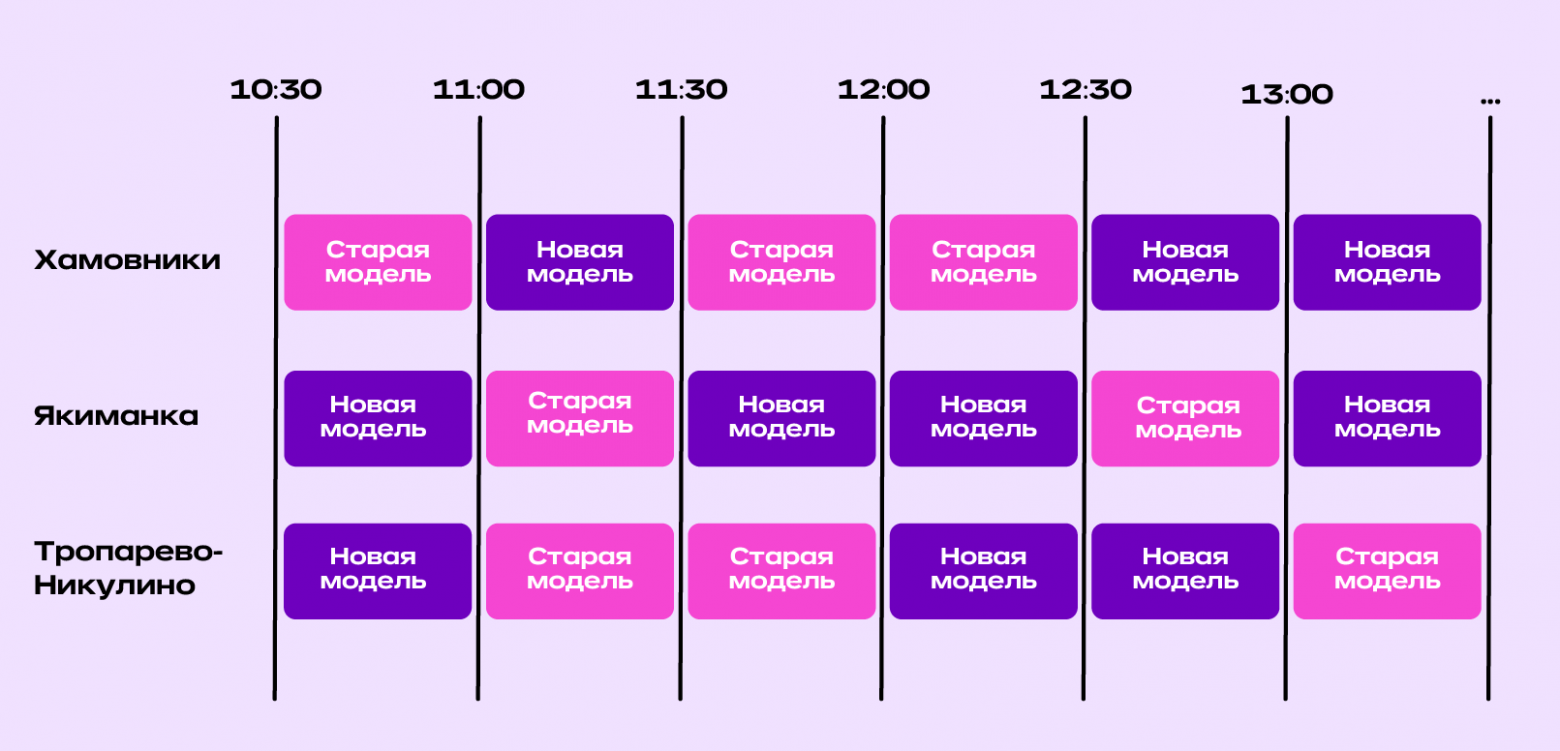

Ключевая проблема, с которой борются Switchback-тесты, — это **сетевые эффекты (Network Effects)**. В двухсторонних маркетплейсах (например, райдшеринг, доставка), где спрос и предложение тесно связаны через **общий ресурс** (например, парк водителей), SUTVA часто нарушается. Если пассажир из тестовой группы, где цены ниже, быстрее делает заказ, он **отнимает ресурс** (водителя) у контрольной группы, косвенно влияя на её показатели (например, увеличивая время ожидания или отмену заказа).

Switchback-тестирование борется с этим эффектом следующим образом:
1.  **Гео-хроно-сплитование:** Вместо деления по пользователям, весь **кластер (географическая зона)** в определённый **временной интервал** получает одно и то же воздействие (либо контроль, либо тест). Это значительно сокращает количество взаимодействий между пользователями, находящимися в разных группах.
2.  **Минимизация взаимодействия:** Цель состоит в том, чтобы каждый кластер был **максимально автономным и независимым** от других. Это можно измерить, например, долей заказов, где ресторан, клиент и курьер находятся в пределах одного кластера. Варьирование границ кластеров (часто вдоль естественных преград, таких как реки или крупные автомагистрали) помогает максимизировать эту автономию.
3.  **Перераспределение во времени:** Поскольку кластеры могут сильно отличаться друг от друга (например, по плотности заказов, погодным условиям), через фиксированные интервалы времени происходит **случайное переключение** группы для каждого кластера. Это позволяет каждому кластеру побывать в обеих группах (тестовой и контрольной) в разные моменты времени, усредняя влияние внешних факторов и повышая надёжность измерений.

В результате, хотя сетевой эффект не устраняется полностью (особенно на границах кластеров или во время переключений), он значительно **сокращается**, что позволяет получать более **валидные и несмещённые оценки** эффектов.

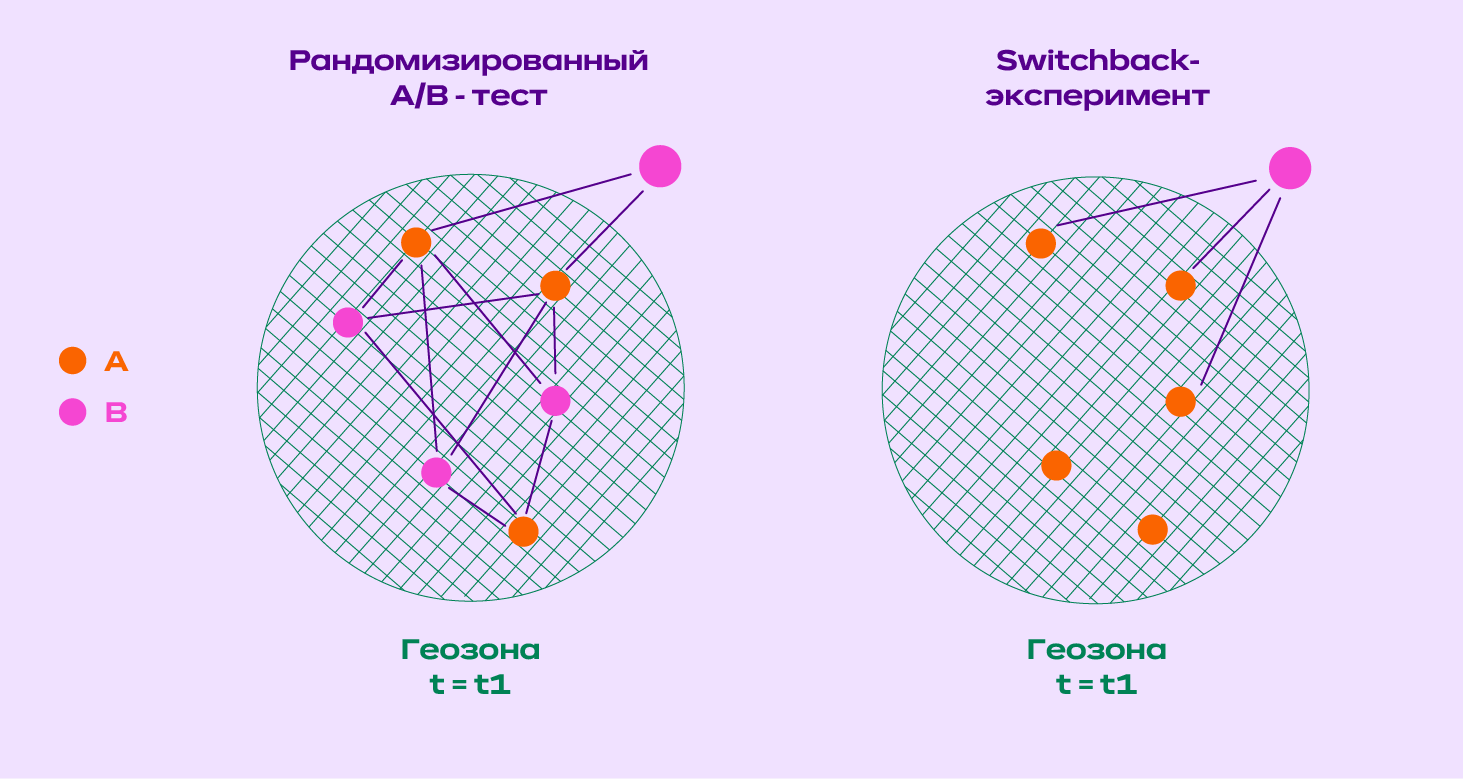

**Вопрос.** Курьерская доставка: заказ от назначения курьера до вручения занимает в среднем 45 минут. Продакт хочет switchback с окном 15 минут: «так мы наберём вчетверо больше юнитов и закончим тест быстрее». Что вы ответите?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Окно 15 минут короче самого эффекта, поэтому почти каждый заказ застанет обе группы, и оценка сместится к нулю. Больше юнитов здесь означает не больше информации, а больше перемешанных наблюдений. Окно берут в несколько раз длиннее целевого действия, например 2–3 часа, а первые минуты после переключения отбрасывают как период переноса. Компромисс есть и в другую сторону: слишком длинное окно даёт мало рандомизаций, поэтому выбор окна проверяют на истории по смещению и разбросу.

</details>

### Эффективность теста
Эффективность Switchback-теста во многом зависит от грамотного выбора параметров кластеризации: временных окон и географических зон.

*   **Временные окна**

    Длительность временного окна — это период, в течение которого кластер непрерывно находится в одной группе (тестовой или контрольной) до следующего случайного переключения.

    Необходимо найти баланс между длительностью интервала и количеством наблюдений.
    *   **Слишком короткий интервал**
        *   Позволяет получить **много измерений** (больше юнитов), что потенциально **снижает дисперсию** метрик и повышает чувствительность теста.
        *   Однако увеличивает **риск "памяти" кластера или "переноса эффекта" (Carryover Effect)**: воздействие предыдущей трактовки может сохраняться и влиять на результаты в текущем периоде. Например, если среднее время доставки заказа составляет 45 минут, а интервал Switchback установлен на 10 минут, то большая часть данных по заказам будет затронута обеими группами, что сделает оценку эффекта затруднительной.
        *   Может привести к **смещённым данным (Bias)**, если алгоритмы, работающие в группах, не успевают стабилизироваться или "исправлять" ситуацию после быстрого переключения.
    *   **Слишком длинный интервал**
        *   **Уменьшает количество доступных наблюдений** (меньше юнитов), что **повышает дисперсию** и снижает статистическую мощность теста.
        *   Однако **снижает риск Carryover Effect**, поскольку даёт больше времени для стабилизации эффектов перед переключением.
    *   **Оптимальная длительность:**
        *   Единого "оптимального" ответа нет; она **зависит от вашей бизнес-системы и тестируемого алгоритма**.
        *   Рекомендуется отталкиваться от **средней длительности целевого действия** (например, среднее время доставки заказа) и брать окно **в несколько раз больше**.

*   **Географические зоны:**
    *   **Независимость кластеров**
    
    Главная цель — создание **автономных географических зон**, где взаимодействие с соседними кластерами минимально.
    *   **Естественные границы**
    
    Часто города делятся на такие кластеры естественными преградами, как реки, крупные автомагистрали, лесополосы, которые интуитивно снижают взаимодействие между зонами.
    *   **Размер кластера**
    
    Выбор оптимального размера также представляет из себя компромисс. Увеличение количества юнитов за счёт меньших зон может уменьшить **[Margin of Error (предельную погрешность выборки)](https://en.wikipedia.org/wiki/Margin_of_error)**, делая доверительные интервалы уже и позволяя точнее оценивать среднее. Однако это увеличивает **[Bias (смещение)](https://en.wikipedia.org/wiki/Bias_of_an_estimator)**: в маленьких зонах больше поездок пересекает границу, и эффект перелива между зонами сильнее. Кроме того, маленькие юниты меньше похожи друг на друга и содержат больше выбросов.

## Методология switchback

**Модель потенциальных исходов для кластеров**

Формальная модель ниже следует работе Bojinov, Simchi-Levi, Zhao «Design and Analysis of Switchback Experiments».

В Switchback-эксперименте **экспериментальной единицей (или "юнитом")** становится не индивидуальный пользователь, а **кластер, определяемый комбинацией географической зоны и временного интервала**. В любой заданный момент времени все пользователи в одном кластере получают одинаковое воздействие (либо тестовое, либо контрольное).

Пусть $t \in \{1, \dots, T\}$ обозначает дискретные временные периоды, а $T$ — общую продолжительность эксперимента. Для каждого временного периода $t$ мы назначаем кластеру воздействие $W_t \in \{0, 1\}$, где $W_t = 1$ соответствует тестовому воздействию, а $W_t = 0$ — контрольному. **Путь назначений** представляет собой вектор $\mathbf{W}_{1:T} = (W_1, W_2, \dots, W_T) \in \{0,1\}^T$.

**Ключевой аспект Switchback-тестирования — эффект последействия (carryover effect)**. Это означает, что воздействие, примененное в предыдущие периоды, может продолжать влиять на результаты в текущем периоде. Мы делаем следующие предположения о потенциальных исходах $Y_t$:

*   **Предположение 1 (Non-anticipating Potential Outcomes):** Исходы в момент времени $t$ не зависят от будущих назначений.

  Формально, для любого $t \in [T]$, $\mathbf{w}_{1:t} \in \{0,1\}^t$, и для любых $\mathbf{w}'_{t+1:T}, \mathbf{w}''_{t+1:T} \in \{0,1\}^{T-t}$ $Y_t(\mathbf{w}_{1:t}, \mathbf{w}'_{t+1:T}) = Y_t(\mathbf{w}_{1:t}, \mathbf{w}''_{t+1:T})$

  Это условие выполняется, поскольку механизм назначения контролируется экспериментатором, и исход в момент $t$ не может зависеть от еще не произошедших назначений.

*   **Предположение 2 ($m$-Carryover Effects)**: Существует фиксированное $m$, такое что исход в момент времени $t$ зависит только от воздействий в течение последних $m+1$ периодов ($W_{t-m}, \dots, W_t$).

  Формально, для любого $t \in \{m+1, \dots, T\}$, $\mathbf{w}_{t-m:T} \in \{0,1\}^{T-t+m+1}$, и для любых $\mathbf{w}'_{1:t-m-1}, \mathbf{w}''_{1:t-m-1} \in \{0,1\}^{t-m-1}$ $Y_t(\mathbf{w}'_{1:t-m-1}, \mathbf{w}_{t-m:T}) = Y_t(\mathbf{w}''_{1:t-m-1}, \mathbf{w}_{t-m:T})$
   
  Это позволяет нам упростить обозначение потенциального исхода до $Y_t(W_{t-m:t})$. Значение $m$ (порядок эффекта последействия) определяется экспертным знанием предметной области, например, эффект динамического ценообразования в райдшеринге обычно рассеивается через 1-2 часа.

*   **Предположение 3 (Bounded Potential Outcomes)**: Потенциальные исходы ограничены некоторой константой $B > 0$. Это техническое предположение, необходимое для оптимизации дизайна и обеспечения корректности статистических выводов.

**Оценка среднего эффекта лечения**

Наша цель — оценить средний эффект от постоянно применяемой новой политики (тестового воздействия) по сравнению с постоянной контрольной политикой. Мы фокусируемся на **среднем причинном эффекте с лагом $p$ (average lag-p causal effect)**, определяемом как:
$$\tau_p(Y) = \frac{1}{T-p} \sum_{t=p+1}^T [Y_t(\mathbf{1}_{p+1}) - Y_t(\mathbf{0}_{p+1})]$$
где $\mathbf{1}_{p+1}$ — вектор из $p+1$ единиц (постоянное тестовое воздействие), а $\mathbf{0}_{p+1}$ — вектор из $p+1$ нулей (постоянное контрольное воздействие). Здесь $p$ представляет собой наше предположение о порядке эффекта последействия $m$.

Мы наблюдаем только один реализованный путь назначений $\mathbf{w}_{1:T}^{\text{obs}}$ и соответствующие наблюдаемые исходы $Y_t^{\text{obs}} = Y_t(\mathbf{w}_{1:T}^{\text{obs}})$. Для оценки $\tau_p(Y)$ мы используем **оценку Хорвица-Томпсона (Horvitz-Thompson estimator, HT-оценка)**, которая "перевзвешивает" каждое наблюдение обратной вероятностью его назначения, чтобы учесть потенциальные неравные вероятности выборки.

В контексте Switchback-экспериментов, для каждого периода $t$, мы определяем вклад в оценку ATE следующим образом, учитывая наблюдаемые исходы $Y_t^{\text{obs}}$ и вероятности пути назначения $\mathbf{w}_{t-p:t}$:
$$\hat{\tau}_p(\eta_{T,Q}, \mathbf{w}_{1:T}, Y) = \frac{1}{T-p} \sum_{t=p+1}^T \left\{ \frac{Y_t^{\text{obs}} \mathbf{1}_{\mathbf{w}_{t-p:t} = \mathbf{1}_{p+1}}}{\Pr(\mathbf{W}_{t-p:t} = \mathbf{1}_{p+1})} - \frac{Y_t^{\text{obs}} \mathbf{1}_{\mathbf{w}_{t-p:t} = \mathbf{0}_{p+1}}}{\Pr(\mathbf{W}_{t-p:t} = \mathbf{0}_{p+1})} \right\}$$
где $\eta_{T,Q}$ — вероятностное распределение пути назначений, определяемое дизайном эксперимента.

**Мощность теста**

В Switchback-экспериментах **мощность** теста зависит от нескольких факторов:

*   **Длительность эксперимента ($T$) и порядок carryover effect ($m$)**: Отношение $T/m$ (количество независимых рандомизаций) напрямую влияет на мощность. Чем больше это отношение, тем выше мощность. Фирмы могут выбирать $T$, ориентируясь на кривую мощности, чтобы достичь желаемого уровня обнаружения эффекта.
*   **Соотношение сигнал/шум**: Чем сильнее эффект воздействия (сигнал) по сравнению с шумом в данных, тем выше мощность. Больший эффект при той же длительности эксперимента даёт более высокую мощность.
*   **Размер выборки (количество юнитов)**: Увеличение количества наблюдений (юнитов) обычно приводит к снижению дисперсии оценки и повышению мощности. Однако, в Switchback-экспериментах количество юнитов ограничено делением по времени и геозонам.
*   **Точность оценки $m$**: Если порядок carryover effect $m$ недооценен, оценка будет смещенной, что может повлиять на мощность. Если $m$ переоценен, оценка остается несмещенной, но дисперсия может быть больше, чем при точном $m$, что также снижает мощность.

**Для оценки применимости и мощности статистических тестов, крайне важны A/A-тесты.** Проводя множество синтетических A/A-тестов на исторических данных (где нет реального эффекта), мы можем получить **распределение p-value**. Если выбранный статистический тест применим, это распределение должно быть **равномерным**. Отклонение от равномерности указывает на то, что **FPR (false positive rate - вероятность ложноположительного результата) НЕ контролируется пороговым значением p-value**, и выводы теста будут невалидными. После подтверждения валидности, A/A-тесты используются для оценки FPR (вероятности ложноположительного результата) и Sensitivity (мощности).

**Построение доверительных интервалов**

Стандартные $t$-тесты на уровне пользователей или заказов **не подходят для switchback-экспериментов**: наблюдения внутри одного юнита получают одно воздействие и зависимы. Агрегация до уровня юнита (кластер+время) убирает эту зависимость, но юниты могут быть разными по объёму (ночь и день), а соседние периоды одного кластера коррелируют. Мы проверим это на A/A-тестах ниже.

Для построения доверительных интервалов и проверки гипотез используются следующие подходы:

*   **Регрессия с кластеризованными стандартными ошибками**: разность средних с фиксированными эффектами зоны и времени и стандартной ошибкой, кластеризованной по зоне. Подход широко используется на практике, но опирается на асимптотику по числу зон.

*   **Точный рандомизационный тест (Exact Inference)**: этот непараметрический тест проверяет гипотезу об отсутствии эффекта в каждый момент времени (sharp null hypothesis). Алгоритм симулирует новые пути назначений, предполагая, что наблюдаемые исходы остаются неизменными при гипотезе отсутствия эффекта. Он позволяет получить точные p-значения.

*   **Асимптотический вывод (Asymptotic Inference)**: Для проверки гипотезы об отсутствии среднего эффекта используется центральная предельная теорема для конечных популяций. При достаточной длительности эксперимента ($T$, чем больше отношение $T/m$, тем лучше) распределение HT-оценки **асимптотически сходится к нормальному распределению**:
  $$\frac{\hat{\tau}_m - \tau_m}{\sqrt{\text{Var}(\hat{\tau}_m)}} \xrightarrow{D} N(0,1)
  $$
  
  где $\text{Var}(\hat{\tau}_m)$ — дисперсия HT-оценки.

  В switchback-экспериментах часто используется оценка Хорвица-Томпсона $\widehat{\tau}_m$ , которая является несмещенной оценкой среднего эффекта воздействия $\tau_{m}$
  
  Используя асимптотическую нормальность оценки и заменяя истинную дисперсию её оценкой $\widehat{\sigma}^2_U$, можно построить $100(1-\alpha)\%$ доверительный интервал для $\tau_m$:

$$
\text{CI}_{100(1-\alpha)\%} = \left[ \widehat{\tau}_m - z_{1-\alpha/2} \sqrt{\widehat{\sigma}^2_U} \text{ ; } \widehat{\tau}_m + z_{1-\alpha/2} \sqrt{\widehat{\sigma}^2_U} \right]
$$
  

Есть 2 подхода к дисперсии для асимптотического вывода:

  1. **Теоретическая формула дисперсии оценки $\text{Var}(\widehat{\tau}_m)$**:

  Для оптимального дизайна при $n = T/m$, где $n \geq 4$ — целое число, дисперсия оценки $\widehat{\tau}_m$ может быть выражена формулой:

$$
\text{Var}(\widehat{\tau}_m) = \frac{1}{(T-m)^2}
\left\{
\bar{Y}_0(1_{m+1})^2 + \bar{Y}_0(0_{m+1})^2 + 2\bar{Y}_0(1_{m+1})\bar{Y}_0(0_{m+1}) \right. \\
\left. + \sum_{k=1}^{n-3} \left[ 3\bar{Y}_k(1_{m+1})^2 + 3\bar{Y}_k(0_{m+1})^2 + 2\bar{Y}_k(1_{m+1})\bar{Y}_k(0_{m+1}) \right] \right. \\
\left. + \bar{Y}_{n-2}(1_{m+1})^2 + \bar{Y}_{n-2}(0_{m+1})^2 + 2\bar{Y}_{n-2}(1_{m+1})\bar{Y}_{n-2}(0_{m+1}) \right. \\
\left. + \sum_{k=0}^{n-3} 2 \left[ \bar{Y}_k(1_{m+1}) + \bar{Y}_k(0_{m+1}) \right] \cdot \left[ \bar{Y}_{k+1}(1_{m+1}) + \bar{Y}_{k+1}(0_{m+1}) \right]
\right\}
$$

  * $T$ — общая длительность эксперимента (количество временных периодов).
  * $m$ — порядок (длительность) перенесенного эффекта (carryover effect), то есть время, в течение которого предыдущее воздействие продолжает влиять на результат.
  * $n = T/m$ — количество "эпох" или блоков экспериментов.
  * $\bar{Y}_k(1_{m+1}) = \sum_{t=(k+1)m+1}^{(k+2)m} Y_t(1_{m+1})$ — сумма по $k$-й эпохе потенциальных результатов при постоянном тестовом воздействии.
  * $\bar{Y}_k(0_{m+1})$ — то же при постоянном контроле.


  2. **Практическая оценка дисперсии (несмещенная оценка верхней границы)**:
Для реальных данных используется **несмещенная оценка консервативной верхней границы дисперсии $\text{Var}(\widehat{\tau}_m)$**, обозначаемая как $\widehat{\sigma}^2_U$:

$$
\widehat{\sigma}^2_U = \frac{1}{(T-m)^2} \left\{
8(\bar{Y}_{obs,0})^2 + \sum_{k=1}^{n-3} 32(\bar{Y}_{obs,k})^2 1_{\{W_{km+1}=W_{(k+1)m+1}\}} + 8(\bar{Y}_{obs,n-2})^2
\right\}
$$

$\quad$ где:
  *   $\bar{Y}_{obs,k} = \sum_{t=(k+1)m+1}^{(k+2)m} Y_{obs,t}$ — сумма **наблюдаемых результатов** в $k$-й эпохе (блоке). Например, $\bar{Y}_{obs,0}$ — это сумма наблюдаемых результатов с периода $m+1$ по $2m$.
  *   $1_{\{W_{km+1}=W_{(k+1)m+1}\}}$ — индикаторная функция, которая равна 1, если назначение воздействия $W$ в начале эпохи $km+1$ было таким же, как и в начале эпохи $(k+1)m+1$, и 0 в противном случае. Это означает, что для среднего члена суммы учитываются только те блоки, где назначение воздействия между смежными точками рандомизации было одинаковым.

   **Комментарий**: Эта оценка $\widehat{\sigma}^2_U$ является несмещенной оценкой верхней границы истинной дисперсии, то есть $E[\widehat{\sigma}^2_U] = \text{Var}_U(\widehat{\tau}_m)$. Её использование позволяет проводить **консервативную оценку статистической значимости**. Оптимальный дизайн switchback-экспериментов предполагает равную вероятность (50/50) назначения лечения или контроля ($q_k = 1/2$), что позволяет избежать проблем со стабильностью оценки Хорвица-Томпсона, которые могут возникнуть, если вероятности близки к 0 или 1.

**Практические рекомендации по выбору размера кластеров и интервала переключения**:

1.  **Длительность интервала переключения (Switchback Window Size)**:
    *   Должен быть **достаточно долгим, чтобы полностью захватить измеряемый эффект**, но **достаточно коротким, чтобы обеспечить достаточное количество выборок** (юнитов) для статистической надежности.
    *   Если интервал слишком короткий, может проявиться **эффект последействия (carryover effect)**, когда влияние предыдущего воздействия сохраняется в следующем периоде, загрязняя данные. Например, если среднее время доставки составляет 45 минут, а период переключения — 10 минут, то почти все данные будут находиться в "периоде перелива" (spillover period), что затруднит интерпретацию.

2.  **Географическая зона (Cluster Size)**:
    *   **Кластеры должны быть максимально автономными**, чтобы минимизировать сетевой эффект между ними. Этого можно достичь, максимизируя долю заказов, когда ресторан, клиент и курьер находятся в одном кластере. Естественные границы (реки, магистрали) часто формируют такие кластеры.
    *   Рандомизация должна покрывать **разное время суток, дни недели и зоны**. Тогда тестовая и контрольная группы одинаково представлены в разные периоды, а сравнение не смешивается с сезонностью.

3.  **"Сжигание" периодов (Burn-in and Burn-out Periods)**:
    *   Для дальнейшего снижения **перекрестного загрязнения (cross-contamination)** между группами, особенно на границах переключения, рекомендуется исключать из анализа данные, собранные в течение коротких "периодов сжигания" в начале и конце каждого интервала воздействия. Например, при часовом окне переключения с 5-минутными периодами сжигания, для анализа используются только данные из средних 50 минут. Это помогает избежать ситуаций, когда пользователь "попадает" под оба воздействия в одной сессии.

4.  **A/A-тестирование**:
    *   Необходимо провести A/A-тесты перед запуском, чтобы проверить **корректность работы платформы и распределение p-value**. Это особенно важно, так как города и районы неравномерны по объёму спроса и предложения.
    *   A/A-тесты также используются для **определения чувствительности тестов** и выбора подходящего интервала переключения.

**Оптимальный дизайн Switchback-эксперимента**

При $m > 0$ и общей длительности эксперимента $T = n\times m$ (где $n \ge 4$ — целое число), оптимальные точки рандомизации $T^*$ будут $\{1, 2m+1, 3m+1, \dots, (n-2)m+1\}$. Это означает, что рандомизация происходит **раз в $m$ периодов**, а первая и последняя эпохи длятся по $2m$. Поэтому частоту рандомизации определяет физическая длительность carryover, а не выбранная гранулярность: если эффект длится 2 часа, то при периоде в час ($m=2$) и в полчаса ($m=4$) перемешивание всё равно происходит раз в 2 часа. Единица времени эксперимента при этом не должна быть длиннее carryover. Вероятность назначения в оптимальном дизайне равна $1/2$.

## Реализация switchback

In [21]:
def make_schedule(n_zones: int, n_periods: int, window: int, rng: np.random.Generator) -> np.ndarray:
    """Назначает воздействие матрицей зона x период: внутри окна длиной window группа не меняется."""
    blocks = int(np.ceil(n_periods / window))
    return np.repeat(rng.integers(0, 2, size=(n_zones, blocks)), window, axis=1)[:, :n_periods]


def simulate_panel(treatment: np.ndarray, effect: float, carryover: int, rng: np.random.Generator,
                   zone_std: float = 3.0, ar_coefficient: float = 0.6, noise_std: float = 1.0) -> np.ndarray:
    """Генерирует метрику: зоны, суточная сезонность, автокоррелированный шум и эффект с задержкой carryover."""
    n_zones, n_periods = treatment.shape
    hours = np.arange(n_periods)
    seasonality = 4 * np.sin(2 * np.pi * hours / 24)
    zone_level = rng.normal(0, zone_std, size=(n_zones, 1))

    noise = np.zeros((n_zones, n_periods))
    shocks = rng.normal(0, noise_std, size=(n_zones, n_periods))
    noise[:, 0] = shocks[:, 0]
    for t in range(1, n_periods):
        noise[:, t] = ar_coefficient * noise[:, t - 1] + shocks[:, t]

    # Эффект равен доле теста среди текущего и carryover прошлых периодов
    kernel = np.ones(carryover + 1) / (carryover + 1)
    exposure = np.apply_along_axis(lambda row: np.convolve(row, kernel)[:n_periods], 1, treatment.astype(float))
    return 20 + zone_level + seasonality + noise + effect * exposure


def within(values: np.ndarray) -> np.ndarray:
    """Убирает фиксированные эффекты зоны и периода."""
    return values - values.mean(axis=1, keepdims=True) - values.mean(axis=0, keepdims=True) + values.mean()


def clustered_estimate(outcome: np.ndarray, treatment: np.ndarray, keep: np.ndarray = None) -> tuple:
    """Оценивает эффект с фиксированными эффектами и стандартной ошибкой, кластеризованной по зоне."""
    keep = np.ones_like(outcome, dtype=bool) if keep is None else keep
    y, w = within(outcome), within(treatment.astype(float))
    w_used = w * keep
    denominator = (w_used * w).sum()
    estimate = (w_used * y).sum() / denominator
    residuals = (y - estimate * w) * keep
    n_zones = len(outcome)
    meat = ((w * residuals).sum(axis=1) ** 2).sum() * n_zones / (n_zones - 1)
    se = np.sqrt(meat) / abs(denominator)
    return estimate, se, 2 * stats.t.sf(abs(estimate / se), n_zones - 1)


def units_ttest(outcome: np.ndarray, treatment: np.ndarray) -> tuple:
    """Обычный t-тест на уровне зона-период, как будто все юниты независимы."""
    result = stats.ttest_ind(outcome[treatment == 1], outcome[treatment == 0])
    return outcome[treatment == 1].mean() - outcome[treatment == 0].mean(), result.pvalue


def burn_mask(treatment: np.ndarray, burn: int) -> np.ndarray:
    """Отмечает наблюдения, которые остаются после отбрасывания burn периодов после переключения."""
    keep = np.ones_like(treatment, dtype=bool)
    switches = np.diff(treatment, axis=1, prepend=treatment[:, :1]) != 0
    for lag in range(burn + 1):
        keep[:, lag:] &= ~switches[:, :treatment.shape[1] - lag]
    keep[:, :burn] = False
    return keep


def randomization_pvalue(outcome: np.ndarray, treatment: np.ndarray, window: int, rng: np.random.Generator, n_draws: int = 300) -> float:
    """Рандомизационный тест: перемешиваем расписание, считая исходы неизменными при нулевой гипотезе."""
    y = within(outcome)

    def statistic(schedule: np.ndarray) -> float:
        w = within(schedule.astype(float))
        return (w * y).sum() / (w * w).sum()

    observed = abs(statistic(treatment))
    draws = [abs(statistic(make_schedule(*outcome.shape, window, rng))) for _ in range(n_draws)]
    return (1 + sum(value >= observed for value in draws)) / (n_draws + 1)

Возьмём 20 зон и 4 недели почасовых данных. У зон разный уровень метрики, есть суточная сезонность, а шум автокоррелирован: соседние часы похожи. Эффект достигает полной величины 1.0 только через 2 часа после включения, это и есть carryover.

Посмотрим на расписание с окном 6 часов и на оценку с разным анализом.

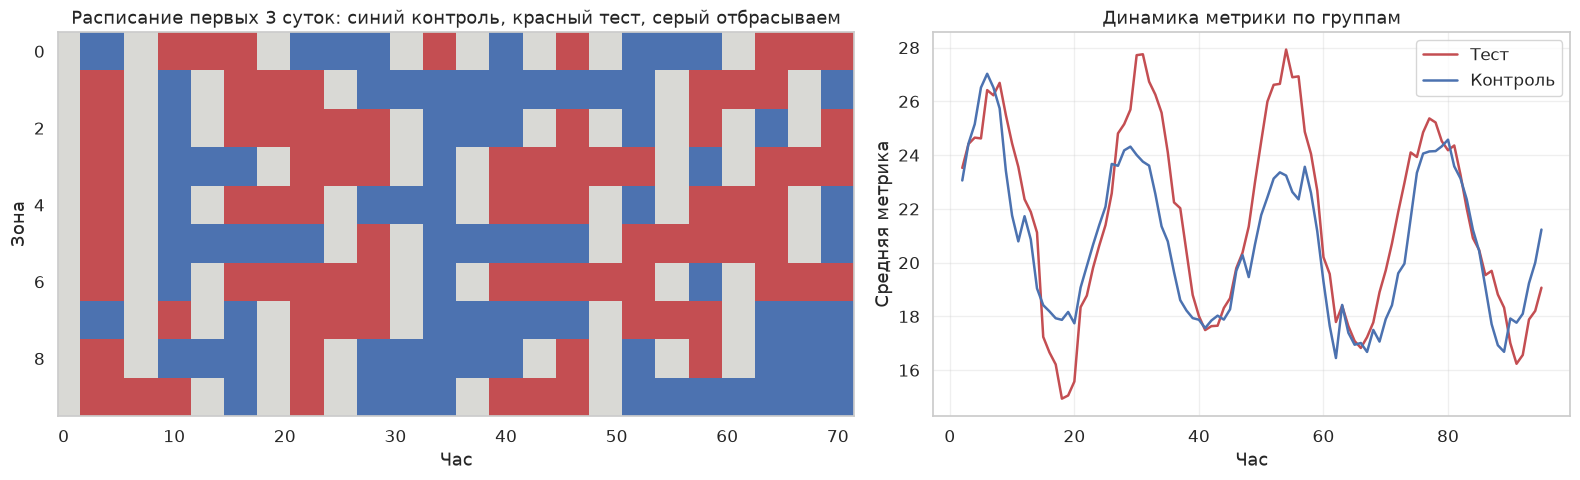

Настоящий эффект: 1.0
Все наблюдения:         0.798 ± 0.082
Без периодов переноса:  0.926 ± 0.109
Рандомизационный тест, p = 0.003


In [22]:
N_ZONES, N_PERIODS, TRUE_EFFECT, CARRYOVER = 20, 24 * 28, 1.0, 2
rng = np.random.default_rng(42)  # своё зерно для части про switchback
window_example = 6

schedule = make_schedule(N_ZONES, N_PERIODS, window_example, rng)
outcome = simulate_panel(schedule, TRUE_EFFECT, CARRYOVER, rng)
keep = burn_mask(schedule, CARRYOVER)

shown = np.where(schedule == 1, 2, 0) * keep + (~keep) * 1
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1.25, 1]})
axes[0].imshow(shown[:10, :72], cmap=ListedColormap([BLUE, '#D9D9D5', RED]), aspect='auto', vmin=0, vmax=2)
axes[0].set(xlabel='Час', ylabel='Зона', title='Расписание первых 3 суток: синий контроль, красный тест, серый отбрасываем')
axes[0].grid(False)

hours = np.arange(N_PERIODS)[:96]
for group, color, label in [(1, RED, 'Тест'), (0, BLUE, 'Контроль')]:
    means = np.ma.array(outcome, mask=~((schedule == group) & keep)).mean(axis=0)
    axes[1].plot(hours, means[:96], color=color, linewidth=1.8, label=label)
axes[1].set(xlabel='Час', ylabel='Средняя метрика', title='Динамика метрики по группам')
axes[1].legend()
plt.tight_layout()
plt.show()

estimate_all = clustered_estimate(outcome, schedule)
estimate_burn = clustered_estimate(outcome, schedule, keep)
print(f'Настоящий эффект: {TRUE_EFFECT}')
print(f'Все наблюдения:         {estimate_all[0]:.3f} ± {1.96 * estimate_all[1]:.3f}')
print(f'Без периодов переноса:  {estimate_burn[0]:.3f} ± {1.96 * estimate_burn[1]:.3f}')
print(f'Рандомизационный тест, p = {randomization_pvalue(outcome, schedule, window_example, rng):.3f}')

**Как выбрать окно переключения**

Короткое окно даёт много рандомизаций, но большая часть данных попадает в перенос, и оценка смещается к нулю. Длинное окно снимает смещение, но рандомизаций становится мало, и шум растёт. Посмотрим на смещение, разброс и итоговую ошибку (RMSE) при разных окнах без отбрасывания данных и с отбрасыванием.

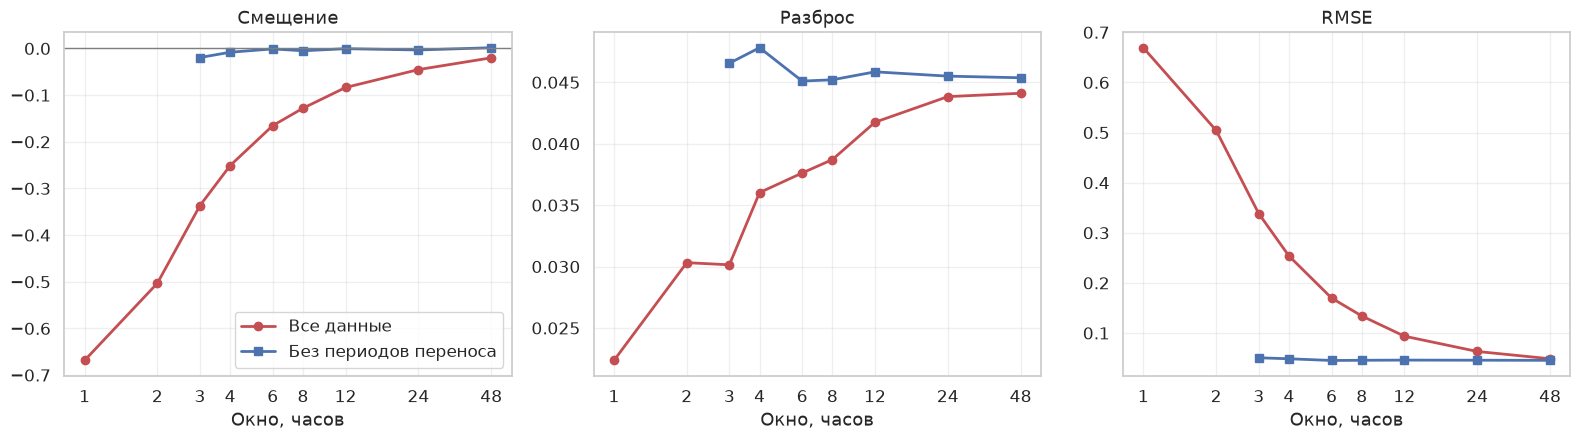

Смещение                          Разброс             \
Анализ Без периодов переноса Все данные Без периодов переноса Все данные   
Окно                                                                       
1                        NaN     -0.669                   NaN      0.022   
2                        NaN     -0.503                   NaN      0.030   
3                     -0.020     -0.337                 0.047      0.030   
4                     -0.008     -0.251                 0.048      0.036   
6                     -0.001     -0.165                 0.045      0.038   
8                     -0.005     -0.128                 0.045      0.039   
12                    -0.001     -0.084                 0.046      0.042   
24                    -0.003     -0.045                 0.045      0.044   
48                     0.001     -0.020                 0.045      0.044   

                        RMSE             
Анализ Без периодов переноса Все данные  
Окно                                     
1                        NaN      0.669  
2                        NaN      0.504  
3                      0.050      0.338  
4                      0.049      0.254  
6                      0.045      0.170  
8                      0.045      0.134  
12                     0.046      0.094  
24                     0.046      0.063  
48                     0.045      0.048

In [23]:
def window_study(windows: list, carryover: int = CARRYOVER, n_sims: int = 500, seed: int = 7) -> pd.DataFrame:
    """Оценивает смещение и разброс оценки эффекта для разных окон переключения."""
    rng = np.random.default_rng(seed)
    rows = []
    for window in windows:
        all_data, without_burn = [], []
        for _ in range(n_sims):
            schedule = make_schedule(N_ZONES, N_PERIODS, window, rng)
            outcome = simulate_panel(schedule, TRUE_EFFECT, carryover, rng)
            all_data.append(clustered_estimate(outcome, schedule)[0])
            if window > carryover:
                without_burn.append(clustered_estimate(outcome, schedule, burn_mask(schedule, carryover))[0])
        for name, values in [('Все данные', all_data), ('Без периодов переноса', without_burn)]:
            if values:
                values = np.array(values)
                rows.append({'Окно': window, 'Анализ': name, 'Смещение': values.mean() - TRUE_EFFECT, 'Разброс': values.std(),
                             'RMSE': np.sqrt(((values - TRUE_EFFECT) ** 2).mean())})
    return pd.DataFrame(rows)


windows = [1, 2, 3, 4, 6, 8, 12, 24, 48]
study = window_study(windows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, metric in zip(axes, ['Смещение', 'Разброс', 'RMSE']):
    for name, color, marker in [('Все данные', RED, 'o'), ('Без периодов переноса', BLUE, 's')]:
        part = study[study['Анализ'] == name]
        ax.plot(part['Окно'], part[metric], color=color, marker=marker, linewidth=2, label=name)
    ax.set_xscale('log', base=2)
    ax.set_xticks(windows, windows)
    ax.set(xlabel='Окно, часов', title=metric)
axes[0].axhline(0, color=GRAY, linewidth=1)
axes[0].legend()
plt.tight_layout()
plt.show()

study.pivot(index='Окно', columns='Анализ', values=['Смещение', 'Разброс', 'RMSE']).round(3)

Что видно на графиках:

* **Без отбрасывания данных** короткое окно сильно занижает эффект: при окне 1 час смещение −0.67, то есть оценка в три раза меньше настоящей. Даже при окне 24 часа смещение −0.045. Причина в том, что значительная часть наблюдений приходится на период, когда эффект ещё не развился.
* **С отбрасыванием периодов переноса** смещение почти исчезает уже при окне 3–4 часа, а RMSE выходит на 0.045 начиная с окна 6 часов.
* **Разброс** при большом окне здесь почти не растёт, потому что в модели шум коррелирует только несколько часов, а сезонность убрана фиксированными эффектами. В реальных данных, с сильной автокорреляцией или при короткой длительности теста, длинное окно обойдётся дороже, поэтому такую проверку стоит делать на своих исторических данных.

Практический вывод совпадает с рекомендацией выше: окно должно быть в несколько раз больше длительности переноса, а сам перенос лучше исключать из анализа.

**A/A-проверка: какому тесту можно верить**

Запустим много A/A-тестов и сравним три способа посчитать p-value: обычный t-тест по юнитам, кластеризованную ошибку и рандомизационный тест. Корректный тест даёт равномерные p-value и 5% ложных срабатываний.

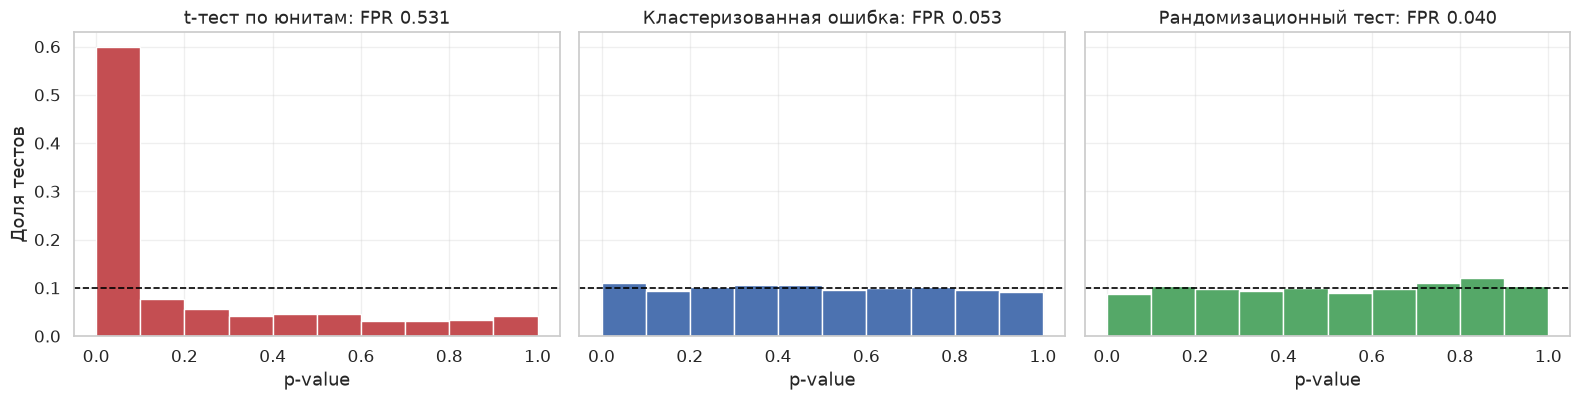

,FPR при α = 5%
t-тест по юнитам,0.531
Кластеризованная ошибка,0.053
Рандомизационный тест,0.040


In [24]:
def aa_study(window: int, n_sims: int = 1500, n_randomization: int = 150, seed: int = 11) -> pd.DataFrame:
    """Считает p-value разных тестов на A/A-экспериментах."""
    rng = np.random.default_rng(seed)
    rows = []
    for sim in range(n_sims):
        schedule = make_schedule(N_ZONES, N_PERIODS, window, rng)
        outcome = simulate_panel(schedule, 0.0, CARRYOVER, rng)
        row = {'t-тест по юнитам': units_ttest(outcome, schedule)[1], 'Кластеризованная ошибка': clustered_estimate(outcome, schedule)[2]}
        if sim < 300:
            row['Рандомизационный тест'] = randomization_pvalue(outcome, schedule, window, rng, n_randomization)
        rows.append(row)
    return pd.DataFrame(rows)


aa_pvalues = aa_study(window=12)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, column, color in zip(axes, aa_pvalues.columns, [RED, BLUE, GREEN]):
    values = aa_pvalues[column].dropna()
    ax.hist(values, bins=np.linspace(0, 1, 11), color=color, weights=np.full(len(values), 1 / len(values)), edgecolor='white')
    ax.axhline(0.1, color='black', linestyle='--', linewidth=1.2)
    ax.set(xlabel='p-value', title=f'{column}: FPR {(values <= ALPHA).mean():.3f}')
axes[0].set_ylabel('Доля тестов')
plt.tight_layout()
plt.show()

aa_pvalues.apply(lambda column: (column.dropna() <= ALPHA).mean()).round(3).to_frame('FPR при α = 5%')

Обычный t-тест по юнитам даёт 53% ложных срабатываний вместо 5%, и распределение его p-value сильно смещено к нулю: юниты одной зоны и соседние часы не независимы. Кластеризованная ошибка (5.3%) и рандомизационный тест (4.0% на 300 экспериментах) контролируют ошибку первого рода. Поэтому агрегации до юнита недостаточно: анализ обязан учитывать структуру рандомизации.

**Оценка Хорвица–Томпсона в оптимальном дизайне**

Проверим формулы Bojinov et al. на одной зоне. Берём оптимальный дизайн, считаем HT-оценку и консервативную оценку дисперсии $\widehat{\sigma}^2_U$. Вероятность того, что все $m+1$ периодов окна получили одно воздействие, равна $2^{-c_t}$, где $c_t$ — число эпох, которые пересекает окно.

In [25]:
def optimal_schedule(n_blocks: int, m: int, rng: np.random.Generator) -> tuple:
    """Строит оптимальный дизайн: T = nm, первая и последняя эпохи длятся 2m."""
    points = np.array([0] + [k * m for k in range(2, n_blocks - 1)])  # индексы рандомизации с нуля
    T = n_blocks * m
    epochs = np.searchsorted(points, np.arange(T), side='right') - 1
    coins = rng.integers(0, 2, len(points))
    return coins[epochs], epochs, coins


def ht_estimate(outcome: np.ndarray, treatment: np.ndarray, epochs: np.ndarray, coins: np.ndarray, m: int) -> tuple:
    """Считает HT-оценку lag-m эффекта и несмещённую оценку верхней границы дисперсии."""
    T, n = len(outcome), len(outcome) // m
    total = 0.0
    for t in range(m, T):
        window_treatment = treatment[t - m:t + 1]
        probability = 0.5 ** len(np.unique(epochs[t - m:t + 1]))
        total += outcome[t] * (int((window_treatment == 1).all()) - int((window_treatment == 0).all())) / probability

    sums = np.array([outcome[(k + 1) * m:(k + 2) * m].sum() for k in range(n - 1)])
    same = coins[:-1] == coins[1:]  # совпали ли соседние рандомизации W_{km+1} и W_{(k+1)m+1}
    variance = 8 * sums[0] ** 2 + 8 * sums[n - 2] ** 2
    variance += 32 * sum(sums[k] ** 2 * same[k - 1] for k in range(1, n - 2))
    return total / (T - m), variance / (T - m) ** 2


def ht_study(n_blocks: int = 120, m: int = 2, n_sims: int = 4000, seed: int = 3) -> pd.Series:
    """Проверяет несмещённость и покрытие доверительного интервала на постоянных потенциальных исходах."""
    rng = np.random.default_rng(seed)
    T = n_blocks * m
    base = 10 + 3 * np.sin(2 * np.pi * np.arange(T) / 24) + rng.normal(0, 1, T)  # исходы фиксированы
    estimates, variances = [], []
    for _ in range(n_sims):
        treatment, epochs, coins = optimal_schedule(n_blocks, m, rng)
        kernel = np.ones(m + 1) / (m + 1)
        exposure = np.convolve(treatment.astype(float), kernel)[:T]
        estimate, variance = ht_estimate(base + TRUE_EFFECT * exposure, treatment, epochs, coins, m)
        estimates.append(estimate)
        variances.append(variance)
    estimates, variances = np.array(estimates), np.array(variances)
    return pd.Series({'Средняя оценка': estimates.mean(), 'Разброс оценки': estimates.std(), 'Средняя σ_U': np.sqrt(variances.mean()),
                      'Покрытие 95% интервала': (np.abs(estimates - TRUE_EFFECT) <= 1.96 * np.sqrt(variances)).mean()})


ht_study().round(3).to_frame('Значение')

,Значение
Средняя оценка,1.012
Разброс оценки,3.900
Средняя σ_U,3.930
Покрытие 95% интервала,0.954


Средняя оценка 1.01 близка к настоящему эффекту 1.0, а консервативная оценка дисперсии работает: покрытие 95% интервала равно 95.4%. Но разброс оценки 3.9 почти вчетверо больше самого эффекта. HT-оценка умножает исход на большие веса, поэтому она чувствительна к уровню метрики и на одной зоне малопригодна. На практике исходы центрируют, используют регрессионные поправки или данные по многим зонам.

### Итоги по switchback

* SUTVA — это условие на потенциальные исходы. При общем ресурсе (водители, курьеры) обычный A/B-тест смещён и может показать эффект там, где его нет.
* Switchback рандомизирует пару «зона–время», и вся зона в окне получает одно воздействие.
* Короткое окно смещает оценку из-за переноса, а длинное уменьшает число рандомизаций. Периоды переноса разумно отбрасывать.
* Единицы одной рандомизации коррелируют, поэтому обычный t-тест по юнитам завышает ошибку первого рода. Перед запуском обязательна A/A-проверка.
* Для анализа используют кластеризованные ошибки, рандомизационный тест или HT-оценку с консервативной дисперсией.
* По Bojinov et al., оптимальная вероятность назначения равна 1/2, а частота рандомизации определяется длительностью carryover.

## Правило для команды

1. **В дизайн-доке две строки: единица рандомизации и единица анализа.** Если они не совпадают (ratio-метрика, кластеры, зона–час), дисперсию считаем на уровне рандомизации: линеаризация или бутстрап по пользователям, агрегация до кластеров, кластеризованные ошибки.
2. **Мощность и MDE считаем по числу кластеров** с эффектом дизайна, ICC берём из истории. «Больше пользователей в тех же кластерах» не аргумент.
3. **Мало кластеров или они сильно разные — не CR1 по умолчанию.** Берём wild cluster bootstrap, CR2, агрегацию или рандомизационный вывод и заранее проверяем, сколько вообще существует разбиений.
4. **Анализ повторяет дизайн**: пары анализируем парным тестом, подбор групп — с ковариатой или перестановками. Перед запуском прогоняем A/A на истории; подозрительно низкая доля ложных срабатываний — такой же сигнал, как высокая.
5. **Общий ресурс (курьеры, водители, склад) — switchback**: окно в несколько раз длиннее переноса эффекта, периоды переноса отбрасываем, анализ на уровне зоны с кластеризацией или перестановками.
6. **Ratio-метрику показываем вместе с числителем и знаменателем**, а решение принимаем по OEC.

Дальше: встреча 4 — когда останавливать тест, последовательный анализ и futility.

## Дополнительно

Ниже разделы, которые углубляют кластерную часть: как строить кластеры на социальном графе и проверять остаточную интерференцию, как устроены геоэксперименты, и что показали кластерные тесты в компаниях. Основная линия встречи без них не рвётся.

### Сценарий: интерференция и кластеры на графе

Если пользователи связаны, важно, как устроены их связи. Запишем потенциальный исход в общем виде: он зависит от всего вектора назначений, $Y_i(\mathbf{z})$. Интересует **глобальный эффект** — разница между миром, где воздействие у всех, и миром, где его нет:

$$
GTE = \frac{1}{n}\sum_i \big(Y_i(\mathbf{1}) - Y_i(\mathbf{0})\big)
$$

В обычном A/B у пользователя половина друзей в тесте, а половина в контроле, поэтому мы не видим ни один из этих миров. Простейшая модель делит эффект на прямой $\tau$ и сетевой $\gamma$:

$$
Y_i = \alpha + \tau z_i + \gamma \cdot \text{доля друзей в тесте} + e_i, \qquad GTE = \tau + \gamma
$$

При индивидуальной рандомизации доля друзей в тесте примерно равна 0.5 у всех, и оценка улавливает только $\tau$. Если друзья находятся в одном кластере, то у тестовых доля близка к 1, а у контрольных к 0, и мы видим почти весь $\gamma$.

Идеальных кластеров нет: граф обычно нельзя разрезать, не задев связей. Качество разбиения измеряют **чистотой (purity)**: долей связей, лежащих внутри кластеров. Именно она определяет, какая часть $\gamma$ видна. При чистоте 0% мы возвращаемся к пользовательскому тесту.

Граф делят алгоритмами кластеризации. **Louvain** жадно максимизирует модулярность и даёт сообщества очень разного размера. Параметр разрешения задаёт, сколько будет кластеров. **Сбалансированное разбиение** (balanced partitioning, reLDG, METIS) даёт равные части. У [Meta](https://ar5iv.labs.arxiv.org/html/2012.08591) Louvain при той же мощности давал большую чистоту, поэтому авторы не советуют настаивать на равных кластерах. [LinkedIn](https://faculty.washington.edu/msaveski/assets/publications/2017_detecting_network_effects/paper.pdf) использует сбалансированный reLDG: при 1000 кластеров внутри них 35.6% связей, а при 10 000 только 21.1%. Заметьте, насколько чистота далека от 100% на реальном графе.

Построим граф с 40 сообществами разного размера и разобьём его с разным разрешением.

Пользователей: 2354, связей: 6868, средняя степень: 5.8


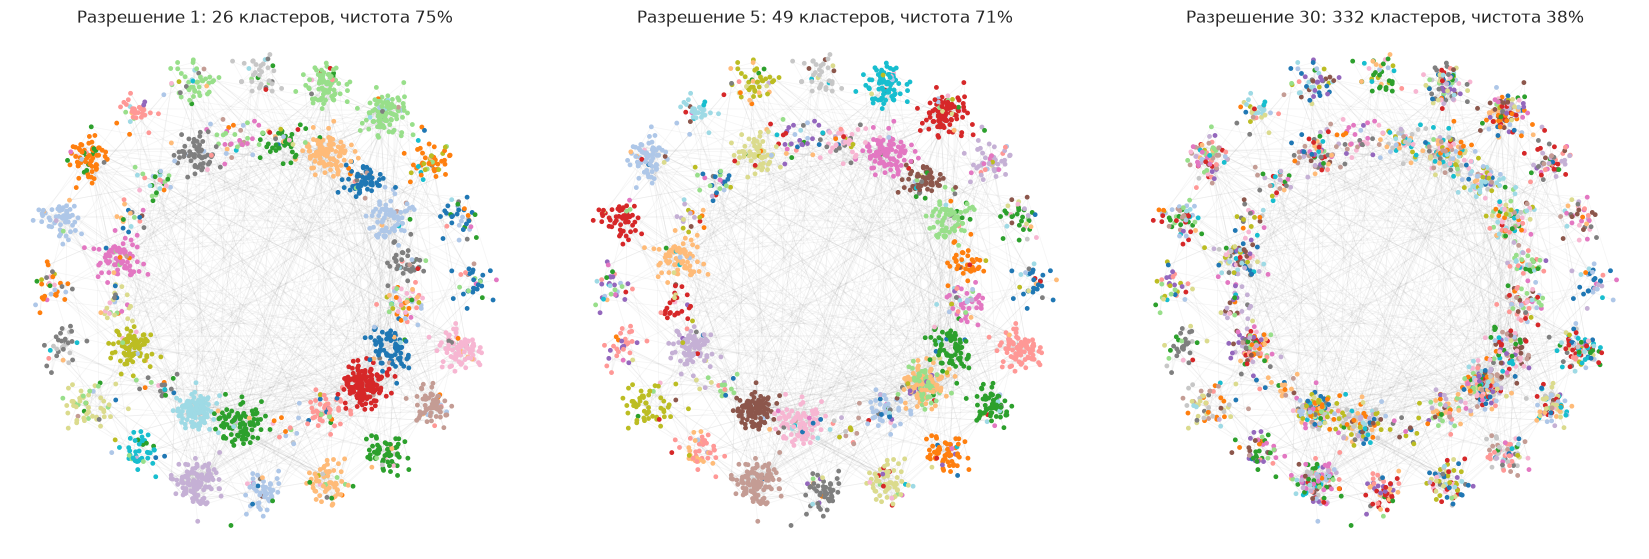

In [26]:
def build_graph(seed=10, communities=40, inside=0.06, outside=0.0006):
    """Создаёт граф сообществ разного размера и его матрицу смежности."""
    local = np.random.default_rng(seed)
    sizes = np.maximum(np.exp(local.normal(4.1, 0.6, communities)), 15).astype(int).tolist()
    probabilities = np.full((communities, communities), outside)
    np.fill_diagonal(probabilities, inside)
    graph = nx.stochastic_block_model(sizes, probabilities.tolist(), seed=seed)
    graph.remove_nodes_from([node for node, degree in dict(graph.degree()).items() if degree == 0])
    return nx.convert_node_labels_to_integers(graph)


graph = build_graph()
adjacency = nx.to_scipy_sparse_array(graph, format='csr', dtype=float)
degree = np.asarray(adjacency.sum(axis=1)).ravel()
block = np.array([graph.nodes[node]['block'] for node in graph.nodes])
print(f'Пользователей: {graph.number_of_nodes()}, связей: {graph.number_of_edges()}, средняя степень: {degree.mean():.1f}')


def partition_labels(resolution):
    communities = nx.community.louvain_communities(graph, resolution=resolution, seed=1)
    labels = np.zeros(graph.number_of_nodes(), dtype=int)
    for index, members in enumerate(communities):
        labels[list(members)] = index
    return labels


def purity(labels):
    rows, cols = adjacency.nonzero()
    return np.mean(labels[rows] == labels[cols])


layout = np.random.default_rng(2)
angles = 2 * np.pi * np.arange(block.max() + 1) / (block.max() + 1)
radius = np.where(np.arange(block.max() + 1) % 2 == 0, 3.2, 2.2)
centers = np.column_stack([radius * np.cos(angles), radius * np.sin(angles)])
positions = centers[block] + layout.normal(0, 0.16, (len(block), 2))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
rows, cols = adjacency.nonzero()
shown = layout.choice(len(rows), 2500, replace=False)
for ax, resolution in zip(axes, [1, 5, 30]):
    labels = partition_labels(resolution)
    ax.plot(np.stack([positions[rows[shown], 0], positions[cols[shown], 0]]), np.stack([positions[rows[shown], 1], positions[cols[shown], 1]]), color=GRAY, alpha=0.08, lw=0.5)
    ax.scatter(*positions.T, c=labels % 20, cmap='tab20', s=6, zorder=3)
    ax.set_aspect('equal')
    ax.set_title(f'Разрешение {resolution}: {labels.max() + 1} кластеров, чистота {purity(labels):.0%}', fontsize=12)
    ax.set_axis_off()
plt.tight_layout()

Теперь оценим компромисс. Мельче кластеры — меньше дисперсия, но ниже чистота и больше смещение. Запустим много симуляций кластерного теста для каждого разбиения с прямым эффектом $\tau = 0.1$ и сетевым $\gamma = 0.1$. Индивидуальная рандомизация — это предельный случай, где каждый пользователь сам себе кластер.

In [27]:
def run_partition(labels, tau=0.1, gamma=0.1, icc=0.02, reps=1000, seed=11):
    """Возвращает среднее и SD оценки разницы средних при данном разбиении."""
    local = np.random.default_rng(seed)
    n, k = len(labels), labels.max() + 1
    home = local.normal(0, np.sqrt(icc), block.max() + 1)[block]
    estimates = np.zeros(reps)
    for rep in range(reps):
        arm = local.permutation(np.arange(k) < k // 2)[labels].astype(float)
        share = adjacency @ arm / np.maximum(degree, 1)
        y = tau * arm + gamma * share + home + local.normal(0, np.sqrt(1 - icc), n)
        estimates[rep] = y[arm == 1].mean() - y[arm == 0].mean()
    return estimates.mean(), estimates.std()


individual_mean, individual_sd = run_partition(np.arange(graph.number_of_nodes()))
rows = [{'Разбиение': 'Индивидуально', 'Кластеров': graph.number_of_nodes(), 'Чистота': 0.0, 'Среднее': individual_mean, 'SD': individual_sd}]
for resolution in [0.3, 1, 3, 5, 10, 30, 100]:
    labels = partition_labels(resolution)
    mean, sd = run_partition(labels)
    rows.append({'Разбиение': f'Louvain {resolution}', 'Кластеров': labels.max() + 1, 'Чистота': purity(labels), 'Среднее': mean, 'SD': sd})
partitions = pd.DataFrame(rows).sort_values('Кластеров').reset_index(drop=True)
partitions['Видимая доля gamma'] = ((partitions['Среднее'] - 0.1) / 0.1).round(3)
partitions.round(3)

,Разбиение,Кластеров,Чистота,Среднее,SD,Видимая доля gamma
0,Louvain 0.3,8,0.841,0.177,0.086,0.768
1,Louvain 1,26,0.752,0.175,0.058,0.755
2,Louvain 3,40,0.744,0.176,0.053,0.756
3,Louvain 5,49,0.711,0.170,0.053,0.696
4,Louvain 10,104,0.534,0.159,0.046,0.588
5,Louvain 30,332,0.377,0.142,0.043,0.420
6,Louvain 100,763,0.265,0.135,0.042,0.352
7,Индивидуально,2354,0.000,0.099,0.040,-0.013


Настоящий глобальный эффект равен 0.20. Индивидуальная рандомизация даёт 0.10: сетевая часть не видна вообще, а SD минимальна, 0.040. Louvain с 40 кластерами и чистотой 74% показывает 0.176 при SD 0.053, то есть почти убирает смещение за небольшую цену. Укрупнение до 8 кластеров мало что добавляет: чистота 84%, а SD выросла до 0.086. Измельчение до 763 кластеров теряет больше половины сетевого эффекта. Видимая доля $\gamma$ близка к чистоте, потому что соседи вне кластера в среднем наполовину в тесте. Чистота считается по рёбрам, а видимая доля по пользователям, поэтому точного совпадения нет.

Какое разбиение лучше, зависит от силы сетевого эффекта. Подвигайте $\gamma$. Смещение линейно зависит от него, а дисперсию мы измерили выше, поэтому ошибку легко пересчитать: $RMSE^2 = \text{смещение}^2 + SD^2$.

In [28]:
def plot_tradeoff(ax, gamma):
    table = partitions.copy()
    table['Смещение'] = gamma * (1 - table['Видимая доля gamma'])
    table['RMSE'] = np.sqrt(table['Смещение'] ** 2 + table['SD'] ** 2)
    ax.plot(table['Кластеров'], table['Смещение'].abs(), 'o-', color=RED, lw=2.2, label='|Смещение|')
    ax.plot(table['Кластеров'], table['SD'], 'o-', color=BLUE, lw=2.2, label='SD')
    ax.plot(table['Кластеров'], table['RMSE'], 'o-', color='black', lw=2.8, label='RMSE')
    best = table.loc[table['RMSE'].idxmin()]
    ax.scatter([best['Кластеров']], [best['RMSE']], s=170, facecolors='none', edgecolors=GREEN, linewidths=2.5, zorder=4, label=f"Лучшее: {best['Кластеров']:.0f} кластеров")
    ax.set_xscale('log')
    ax.set_xlabel('Число кластеров')
    ax.set_ylabel('Ошибка оценки GTE')
    ax.set_title(f'Сетевой эффект γ = {gamma}', fontsize=12)
    ax.legend(fontsize=10)


def tradeoff_demo(gamma=0.1):
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    plot_tradeoff(ax, gamma)
    plt.show()


interact(tradeoff_demo, gamma=FloatSlider(value=0.1, min=0, max=0.5, step=0.01, description='γ'));

interactive(children=(FloatSlider(value=0.1, description='γ', max=0.5, step=0.01), Output()), _dom_classes=('w…

Статичная версия для слабого, среднего и сильного сетевого эффекта.

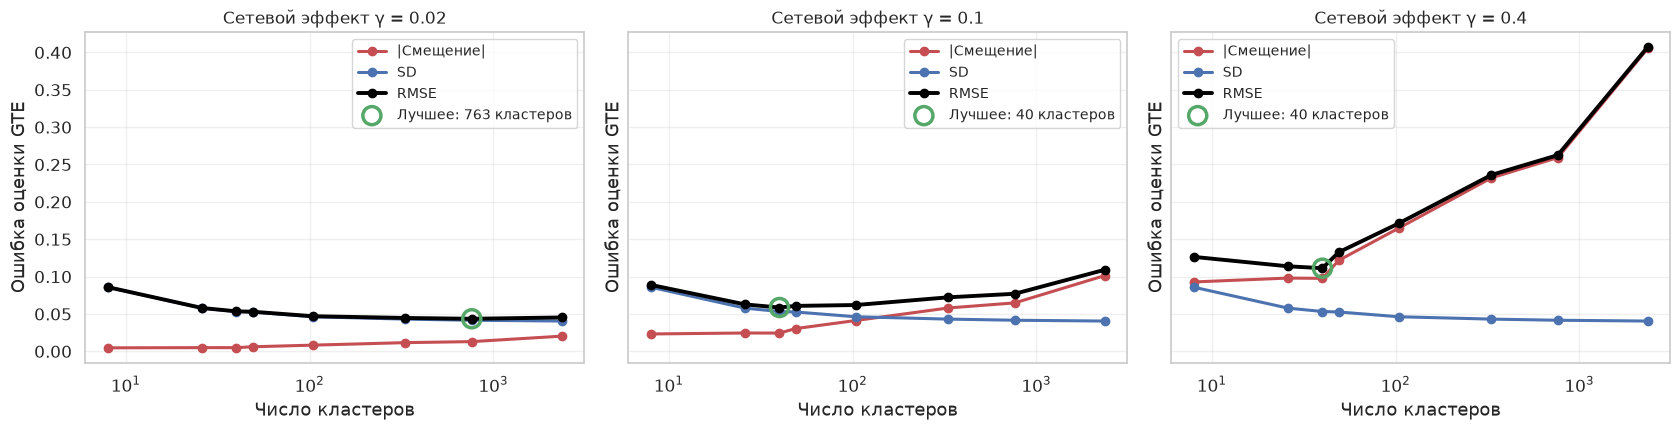

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, gamma in zip(axes, [0.02, 0.1, 0.4]):
    plot_tradeoff(ax, gamma)
plt.tight_layout()

При слабом сетевом эффекте ($\gamma = 0.02$) выгодны мелкие кластеры: смещение мало, и лучше 763 кластера. При среднем и сильном эффекте лучше всего 40 кластеров, совпадающих с настоящими сообществами. Там виден излом: дальше кластеры дробятся, и смещение резко растёт. Настоящую силу эффекта мы заранее не знаем, поэтому полезны проверки из следующего раздела.

Именно этот компромисс разбирает [работа Вивиано и соавторов](https://arxiv.org/abs/2310.14983). Они показывают, что худшее смещение определяется долей соседей вне кластера, а дисперсия — суммой квадратов размеров кластеров, и выбирать кластеры надо под задачу оценки эффекта, а не под поиск сообществ.

Несколько практических приёмов.

* **Назначаем по кластеру, а воздействуем по пользователю.** [Meta](https://medium.com/@AnalyticsAtMeta/how-meta-tests-products-with-strong-network-effects-96003a056c2c) рандомизирует кластеры, но показывает функцию отдельным пользователям, поэтому привычные пользовательские метрики сохраняются. Такой подход там используют для чатов и звонков с 2018 года.
* **Назначаем по признаку.** На маркетплейсах граф двудольный, поэтому строят кластеры похожих объявлений. В [мета-эксперименте Airbnb](https://business.columbia.edu/faculty/research/reducing-interference-bias-online-marketplace-experiments-using-cluster) с ростом комиссии минимум 20% индивидуальной оценки оказалось интерференционным смещением, а чем лучше кластеры, тем сильнее его снижает кластеризация.
* **Анализ тоже может снижать смещение.** Можно учитывать долю соседей в тесте, оценивая эффект только на тех, чьё окружение близко к миру полного воздействия. Но [Эклс, Каррер и Угандер](https://arxiv.org/abs/1404.7530) в симуляциях находят, что дизайн снижает смещение сильнее, чем анализ. Строгую оценку через вероятности экспозиции предлагают [Угандер и соавторы (2013)](https://arxiv.org/abs/1305.6979): оценка Хорвица — Томпсона с вероятностью того, что всё окружение пользователя в нужной группе. Она несмещена, если модель экспозиции верна.

### Проверка остаточной интерференции

Кластеры не убирают интерференцию полностью, поэтому хочется её измерить. Для этого есть два дизайна.

**Тест LinkedIn: рандомизация поверх рандомизации.** [Савески и соавторы (2017)](https://faculty.washington.edu/msaveski/assets/publications/2017_detecting_network_effects/paper.pdf) делят кластеры на две руки: в одной индивидуальная рандомизация, в другой кластерная. Если SUTVA выполнено, обе оценивают одно и то же. Поэтому проверяем нулевую гипотезу о равенстве:

$$
T = \frac{\hat{\mu}_{CR} - \hat{\mu}_{CBR}}{\sqrt{\hat{\sigma}^2_{CR} + \hat{\sigma}^2_{CBR}}}
$$

Статья даёт оценки сверху для дисперсии, чтобы ошибка первого рода не превышала заданную. В первом из двух экспериментов на LinkedIn гипотезу отвергнуть не удалось, а во втором разница оказалась значимой. Аналогичное сравнение есть и у [Meta](https://ar5iv.labs.arxiv.org/html/2012.08591): в эксперименте со Stories эффект на авторов составил -6.37% при кластерной рандомизации и незначимые +0.73% при индивидуальной.

**Двухэтапная рандомизация.** [Хадженс и Холлоран (2008)](https://pmc.ncbi.nlm.nih.gov/articles/PMC2600548) вводят дизайн для **частичной интерференции**: пользователи влияют друг на друга только внутри кластера. Сначала кластеру случайно назначается доля тестовых $\alpha$, затем внутри него случайно выбираются пользователи. Пусть $\bar{Y}(z, \alpha)$ — средний исход пользователя с назначением $z$ в кластере с долей $\alpha$. Тогда определены четыре эффекта:

$$
\begin{align}
\text{Прямой:} & \quad \bar{Y}(1, \alpha) - \bar{Y}(0, \alpha) \\
\text{Косвенный:} & \quad \bar{Y}(0, \alpha_1) - \bar{Y}(0, \alpha_0) \\
\text{Полный:} & \quad \bar{Y}(1, \alpha_1) - \bar{Y}(0, \alpha_0) \\
\text{Общий:} & \quad \bar{Y}(\alpha_1) - \bar{Y}(\alpha_0)
\end{align}
$$

Полный эффект равен сумме прямого эффекта при доле $\alpha_1$ и косвенного. Такой дизайн показывает, как работает воздействие на невыбранных, но требует много кластеров. Проверим оба дизайна на нашем графе, зная истину.

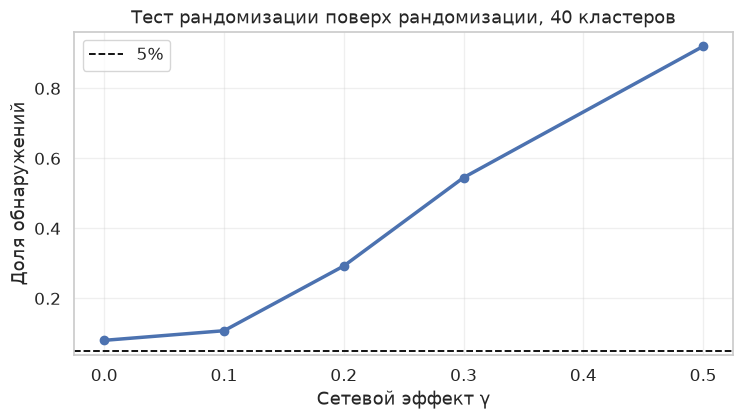

,Средняя разница,Доля отклонений H0
gamma,,
0.0,0.004,0.080
0.1,0.076,0.108
0.2,0.149,0.292
0.3,0.222,0.545
0.5,0.368,0.920


In [30]:
base_labels = partition_labels(3)
block_noise = np.random.default_rng(20).normal(0, np.sqrt(0.02), block.max() + 1)[block]
k_base = base_labels.max() + 1


def linkedin_test(gamma, tau=0.1, reps=400, seed=12):
    """Сравнивает индивидуальную и кластерную руку и возвращает разницу и долю отклонений H0."""
    local = np.random.default_rng(seed)
    n = len(base_labels)
    gaps, rejected = [], []
    for _ in range(reps):
        order = local.permutation(k_base)
        cluster_arm = np.zeros(k_base, bool)
        cluster_arm[order[:k_base // 2]] = True
        in_cluster_arm = cluster_arm[base_labels]
        z = local.random(n) < 0.5
        members = np.flatnonzero(cluster_arm)
        z[in_cluster_arm] = False
        chosen = local.permutation(members)[:len(members) // 2]
        z |= np.isin(base_labels, chosen)
        z = z.astype(float)
        y = tau * z + gamma * (adjacency @ z / np.maximum(degree, 1)) + block_noise + local.normal(0, 1, n)

        individual = ~in_cluster_arm
        mu_cr = y[individual & (z == 1)].mean() - y[individual & (z == 0)].mean()
        var_cr = y[individual & (z == 1)].var() / (individual & (z == 1)).sum() + y[individual & (z == 0)].var() / (individual & (z == 0)).sum()

        table = pd.DataFrame({'c': base_labels[in_cluster_arm], 'y': y[in_cluster_arm], 'z': z[in_cluster_arm]}).groupby('c').agg(s=('y', 'sum'), n=('y', 'size'), z=('z', 'first'))
        s, m, arm = table['s'].to_numpy(), table['n'].to_numpy(float), table['z'].to_numpy() == 1
        r1, r0 = s[arm].sum() / m[arm].sum(), s[~arm].sum() / m[~arm].sum()
        var_cbr = ((s[arm] - r1 * m[arm]) ** 2).sum() / m[arm].sum() ** 2 + ((s[~arm] - r0 * m[~arm]) ** 2).sum() / m[~arm].sum() ** 2
        gaps.append(r1 - r0 - mu_cr)
        clusters_in_arm = len(m)
        var_cbr *= clusters_in_arm / (clusters_in_arm - 1)
        rejected.append(abs(gaps[-1]) / np.sqrt(var_cr + var_cbr) > st.t.ppf(0.975, clusters_in_arm - 2))
    return np.mean(gaps), np.mean(rejected)


gammas = [0, 0.1, 0.2, 0.3, 0.5]
linkedin = pd.DataFrame([dict(zip(['Средняя разница', 'Доля отклонений H0'], linkedin_test(gamma)), gamma=gamma) for gamma in gammas]).set_index('gamma')

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(linkedin.index, linkedin['Доля отклонений H0'], 'o-', color=BLUE, lw=2.5)
ax.axhline(0.05, color='black', ls='--', lw=1.3, label='5%')
ax.set_xlabel('Сетевой эффект γ')
ax.set_ylabel('Доля обнаружений')
ax.set_title(f'Тест рандомизации поверх рандомизации, {k_base} кластеров')
ax.legend()
plt.show()
linkedin.round(3)

In [31]:
def two_stage(gamma, tau=0.1, low=0.2, high=0.8, reps=500, seed=13):
    """Оценивает эффекты двухэтапной рандомизации, усредняя по симуляциям."""
    local = np.random.default_rng(seed)
    n = len(base_labels)
    rows = []
    for _ in range(reps):
        share_cluster = local.permutation(np.where(np.arange(k_base) < k_base // 2, low, high))
        alpha = share_cluster[base_labels]
        z = (local.random(n) < alpha).astype(float)
        y = tau * z + gamma * (adjacency @ z / np.maximum(degree, 1)) + block_noise + local.normal(0, 1, n)
        y11, y10 = y[(z == 1) & (alpha == high)].mean(), y[(z == 1) & (alpha == low)].mean()
        y01, y00 = y[(z == 0) & (alpha == high)].mean(), y[(z == 0) & (alpha == low)].mean()
        rows.append({'Прямой при высокой доле': y11 - y01, 'Прямой при низкой доле': y10 - y00,
                     'Косвенный на контрольных': y01 - y00, 'Полный': y11 - y00})
    table = pd.DataFrame(rows)
    table['Оценка глобального эффекта'] = table['Прямой при низкой доле'] + table['Косвенный на контрольных'] / (high - low)
    return table


stages = two_stage(0.3)
summary = stages.agg(['mean', 'std']).T.rename(columns={'mean': 'Оценка', 'std': 'SD'})
print('Истина: прямой 0.10, сетевой эффект 0.30, глобальный 0.40')
summary.round(3)

Истина: прямой 0.10, сетевой эффект 0.30, глобальный 0.40


,Оценка,SD
Прямой при высокой доле,0.101,0.076
Прямой при низкой доле,0.104,0.074
Косвенный на контрольных,0.133,0.091
Полный,0.234,0.068
Оценка глобального эффекта,0.325,0.179


**Тест LinkedIn.** При $\gamma = 0$ доля отклонений 8%, немного выше 5%: в каждой руке только 20 кластеров, и это та же проблема малого числа кластеров. При $\gamma = 0.5$ тест находит эффект в 92% случаев, а при $\gamma = 0.1$ только в 11%. Поэтому незначимый результат не доказывает отсутствие интерференции. Вспомните, что LinkedIn в первом эксперименте тоже не отверг гипотезу.

**Двухэтапный дизайн.** Прямой эффект оценён верно: 0.10. Полный эффект 0.234 равен сумме прямого при высокой доле (0.101) и косвенного (0.133). Оценка глобального эффекта равна 0.325 при настоящих 0.40, и это не случайность. Дизайн предполагает частичную интерференцию, то есть что связи внутри кластера, а здесь чистота 74%. Поэтому видна примерно такая часть сетевого эффекта: $0.1 + 0.3 \cdot 0.75 = 0.325$. Заодно видно, что SD оценки 0.18 велика: чтобы разделить эффекты, нужно много кластеров.

### Сценарий: геоэксперименты

В геоэксперименте кластер — это регион: город, область, почтовый индекс. Подход используют, когда нельзя таргетировать пользователя: офлайн-продажи, ТВ, наружная реклама, цены, доставка. Классическая работа — [Вавер и Кёлер (2011)](https://research.google/pubs/measuring-ad-effectiveness-using-geo-experiments/) из Google.

Отличия от других сценариев:

* **регионов мало**: в США это 210 зон DMA, а в других странах обычно десятки единиц, причём пригодных для теста ещё меньше;
* **они очень разные**: крупнейший город может быть больше десятка малых вместе;
* **есть длинная история**: метрику региона мы видим за месяцы до теста, и это главный ресурс снижения дисперсии;
* **воздействие протекает через границы**: люди ездят и заказывают из соседнего региона.

#### Дизайн и оценка

Обычно есть **период до теста** и **период теста**. Модель геоэксперимента (Geo-Based Regression, GBR):

$$
y_{i,1} = \beta_0 + \beta_1 y_{i,0} + \beta_2 \delta_i + \epsilon_i
$$

где $y_{i,0}$ и $y_{i,1}$ — метрика региона до и во время теста, а $\delta_i$ — величина воздействия в регионе. В рекламе это разница в затратах, и тогда $\beta_2$ равно окупаемости. Важно, что $\delta_i$ масштабируется с регионом: ниже мы берём $\delta_i = T_i y_{i,0}$, и $\beta_2 / \beta_1$ даёт относительный эффект. Веса берут обратно пропорциональными размеру региона $1/y_{i,0}$. По сути это ANCOVA и CUPED на уровне регионов. Вавер и Кёлер отмечают, что грамотное формирование групп до назначения может сузить интервал на 10% и больше, а дисперсию можно оценить заранее, разрезая историю на псевдопериоды.

Когда регионов совсем мало, например один тестовый город, используют временные ряды:

* **Time-Based Regression (TBR)** [Google](https://research.google/pubs/estimating-ad-effectiveness-using-geo-experiments-in-a-time-based-regression-framework/): предсказывает контрфактический ряд теста по контрольным регионам;
* **Синтетический контроль** и его расширение **GeoLift** от [Meta](https://rdrr.io/github/facebookincubator/GeoLift/f/website/docs/Methodology/Methodology.md): подбирает веса контрольных рынков и проводит анализ мощности для разных наборов регионов;
* **Trimmed Match** от [Google](https://pdf.arxiv.org/pdf/2105.07060): парный дизайн с отбрасыванием пар, которые плохо сравнимы. Он нужен, потому что распределение регионов имеет тяжёлые хвосты.

Смоделируем 60 регионов с тяжёлым хвостом размеров: год недельной истории и 6 недель теста. Сравним четыре подхода по MDE относительного эффекта.

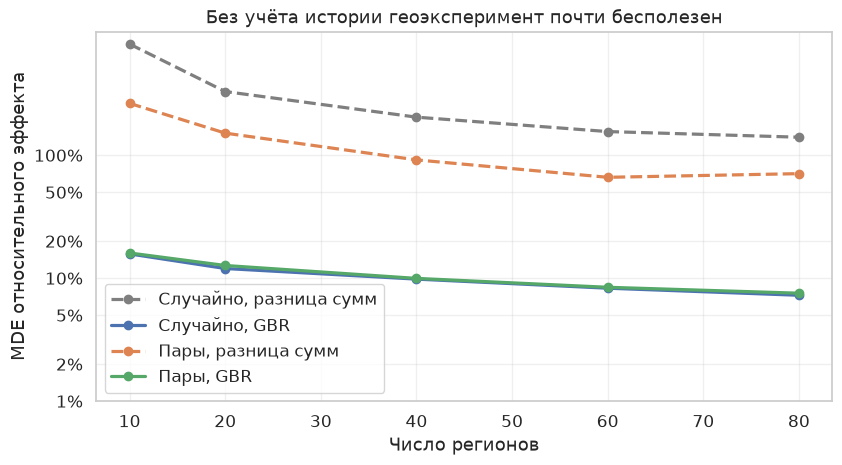

,"Случайно, разница сумм","Случайно, GBR","Пары, разница сумм","Пары, GBR"
10,801.1,15.7,263.9,16.0
20,329.2,12.0,151.1,12.7
40,203.8,9.8,91.6,10.0
60,155.6,8.3,66.1,8.4
80,140.1,7.3,70.8,7.5


In [32]:
def geo_panel(regions, local, weeks=58):
    """Генерирует продажи регионов по неделям: общий сезон, индивидуальные тренды и шум."""
    size = np.sort(np.exp(local.normal(0, 1.3, regions)))[::-1] * 1000
    time = np.arange(weeks)
    season = 1 + 0.12 * np.sin(2 * np.pi * time / 52) + 0.0015 * time
    loading = local.normal(1, 0.25, regions)
    trend = local.normal(0, 0.001, regions)
    shock = local.normal(0, 0.03, weeks)
    drift = np.zeros((weeks, regions))
    for week in range(1, weeks):
        drift[week] = 0.92 * drift[week - 1] + local.normal(0, 0.025, regions)
    level = np.outer(season, np.ones(regions)) + np.outer(shock, loading) + np.outer(time, trend) + drift
    noise = local.normal(0, 1, (weeks, regions)) * (0.05 + 0.6 / np.sqrt(size))
    return size * level * (1 + noise)


def gbr_lift(pre, post, arm):
    """Оценивает относительный эффект регрессией y1 на y0 и δ = T * y0 с весами 1/y0."""
    design = np.column_stack([np.ones(len(pre)), pre, arm * pre])
    root = np.sqrt(1 / pre)
    beta = np.linalg.lstsq(design * root[:, None], post * root, rcond=None)[0]
    return beta[2] / beta[1]


def geo_lifts(regions, reps=1500, pre_weeks=52, seed=14):
    """Считает разброс оценок эффекта при нулевом воздействии для разных подходов."""
    local = np.random.default_rng(seed)
    result = {name: [] for name in ['Случайно, разница сумм', 'Случайно, GBR', 'Пары, разница сумм', 'Пары, GBR']}
    for _ in range(reps):
        panel = geo_panel(regions, local)
        pre, post = panel[:pre_weeks].sum(axis=0), panel[pre_weeks:].sum(axis=0)
        random_arm = local.permutation(np.arange(regions) < regions // 2)
        order = np.argsort(-pre)[:regions - regions % 2]
        flip = local.random(regions // 2) < 0.5
        pair_arm = np.zeros(regions, bool)
        pair_arm[order[np.arange(0, len(order), 2) + flip]] = True
        for label, arm in [('Случайно', random_arm), ('Пары', pair_arm)]:
            control = ~arm
            result[f'{label}, разница сумм'].append((post[arm].sum() - post[control].sum()) / post[control].sum())
            result[f'{label}, GBR'].append(gbr_lift(pre, post, arm))
    return {name: 2.8 * np.std(values) for name, values in result.items()}


region_counts = [10, 20, 40, 60, 80]
geo_mde = pd.DataFrame({regions: geo_lifts(regions) for regions in region_counts}).T

fig, ax = plt.subplots(figsize=(9.5, 4.8))
for column, color, style in zip(geo_mde.columns, [GRAY, BLUE, ORANGE, GREEN], ['--', '-', '--', '-']):
    ax.plot(geo_mde.index, geo_mde[column] * 100, 'o', ls=style, color=color, lw=2.3, label=column)
ax.set_yscale('log')
ax.set_yticks([1, 2, 5, 10, 20, 50, 100], ['1%', '2%', '5%', '10%', '20%', '50%', '100%'])
ax.set_xlabel('Число регионов')
ax.set_ylabel('MDE относительного эффекта')
ax.set_title('Без учёта истории геоэксперимент почти бесполезен')
ax.legend()
plt.show()
(geo_mde * 100).round(1)

Без учёта истории результат бессмыслен: при 40 регионах MDE 204%. Суммы по группам определяются тем, куда попали самые крупные регионы, а пары по размеру только вдвое улучшают ситуацию. Регрессия на историю снижает MDE до 10%. При этом пары по размеру поверх регрессии уже не добавляют точности: вся информация о размере и так учтена.

Дальше MDE падает медленно: 10% при 40 регионах и 7.3% при 80. Шум определяется в основном крупными регионами, и новые мелкие мало что дают. Модель здесь иллюстративная, но порядок величин совпадает с практикой: у Avito в региональном тесте MDE выручки 8.5%, хотя условия и метрики другие.

Посмотрим на тест подробнее. Берём 40 регионов и пары, в тест идёт половина, настоящий эффект +5% за 6 недель. График показывает один запуск, а оценка в заголовке усреднена по 300 запускам. Контрфакт строим по TBR: обучаем связь суммы тестовых регионов с суммой контрольных на истории и прогнозируем период теста. Подвигайте эффект, а вторым параметром задайте утечку: часть эффекта, которая перетекает в контрольные регионы через границы.

In [33]:
def geo_case(effect, leak, regions=40, pre_weeks=52, seed=15):
    """Строит один геоэксперимент и контрфакт по контрольным регионам."""
    local = np.random.default_rng(seed)
    panel = geo_panel(regions, local)
    order = np.argsort(-panel[:pre_weeks].sum(axis=0))
    flip = local.random(regions // 2) < 0.5
    arm = np.zeros(regions, bool)
    arm[order[np.arange(0, regions, 2) + flip]] = True
    panel = panel.copy()
    panel[pre_weeks:, arm] *= 1 + effect
    panel[pre_weeks:, ~arm] *= 1 + effect * leak
    test, control = panel[:, arm].sum(axis=1), panel[:, ~arm].sum(axis=1)
    slope, intercept = np.polyfit(control[:pre_weeks], test[:pre_weeks], 1)
    counterfactual = intercept + slope * control
    return test, counterfactual, test[pre_weeks:].sum() / counterfactual[pre_weeks:].sum() - 1


def plot_geo_case(ax, effect, leak, runs=300):
    test, counterfactual, _ = geo_case(effect, leak)
    lifts = np.array([geo_case(effect, leak, seed=run)[2] for run in range(100, 100 + runs)])
    weeks = np.arange(len(test))
    ax.plot(weeks[30:], test[30:] / 1000, color=BLUE, lw=2.2, label='Тестовые регионы')
    ax.plot(weeks[30:], counterfactual[30:] / 1000, color=RED, lw=2.2, label='Контрфакт')
    ax.axvline(51.5, color=GRAY, ls=':', lw=2)
    ax.set_title(f'Эффект {effect:.0%}, утечка {leak:.0%}: средняя оценка {lifts.mean():.1%}, SD {lifts.std():.1%}', fontsize=12)
    ax.set_xlabel('Неделя')
    ax.set_ylabel('Продажи, тыс.')
    ax.legend(fontsize=10)


def geo_demo(effect=0.05, leak=0.0):
    fig, ax = plt.subplots(figsize=(9, 4.3))
    plot_geo_case(ax, effect, leak)
    plt.show()


interact(geo_demo,
         effect=FloatSlider(value=0.05, min=0, max=0.2, step=0.01, description='Эффект'),
         leak=FloatSlider(value=0, min=0, max=0.6, step=0.05, description='Утечка'));

interactive(children=(FloatSlider(value=0.05, description='Эффект', max=0.2, step=0.01), FloatSlider(value=0.0…

Статичная версия: без утечки и с утечкой 30%.

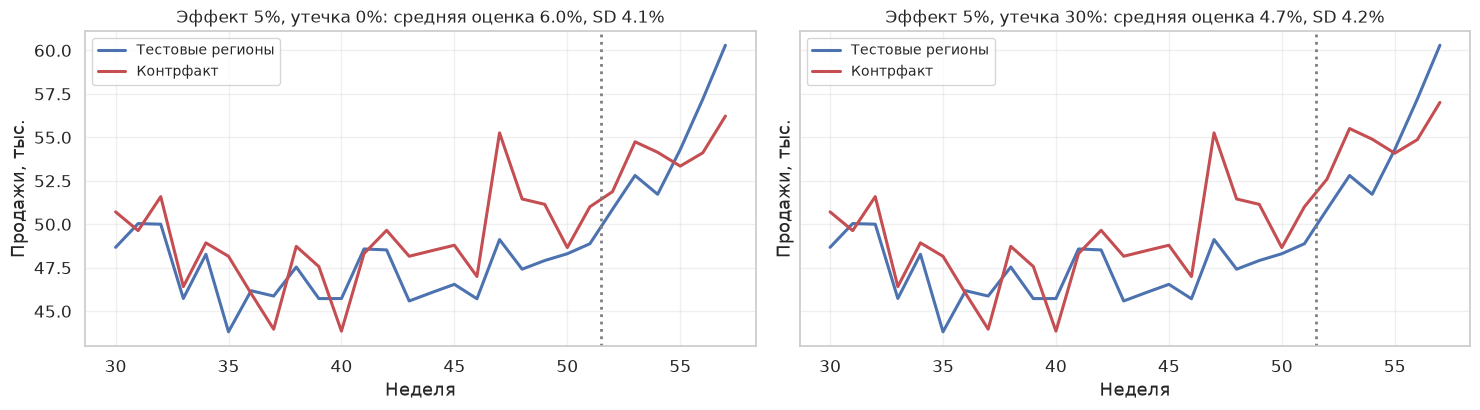

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for ax, leak in zip(axes, [0, 0.3]):
    plot_geo_case(ax, 0.05, leak)
plt.tight_layout()

Без утечки средняя оценка равна 6.0% при настоящих 5%, а SD 4.1%. Завышение на 1 п.п. — свойство такого простого TBR: шум в контрольном ряду занижает наклон, и контрфакт немного отстаёт от роста. Поэтому метод надо проверять на искусственном эффекте. Утечка 30% снижает оценку до 4.7%: контрольные регионы тоже выросли, и разница уменьшилась. Если подозреваете утечку, оставляйте между тестом и контролем буферные регионы или выбирайте изолированные рынки.

#### Проверка: плацебо по датам

У геотеста одна реализация назначений, поэтому важна проверка на истории. Сдвигаем период теста в прошлое и считаем «эффект», которого не было. Разброс таких оценок показывает реальный шум метода и заодно подсказывает MDE ещё до запуска. Вавер и Кёлер используют ту же идею псевдопериодов.

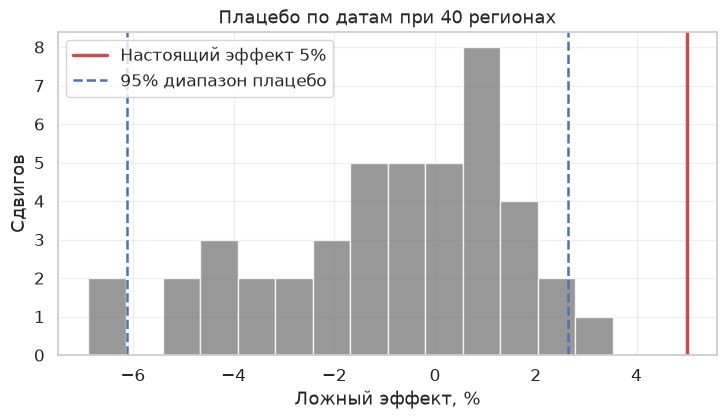

Плацебо: среднее -0.90%, SD 2.40%, MDE примерно 6.7%


In [35]:
def date_placebo(regions=40, seed=16, weeks_test=6, train=26):
    """Сдвигает период теста по истории и считает ложный эффект TBR."""
    local = np.random.default_rng(seed)
    panel = geo_panel(regions, local, weeks=120)
    order = np.argsort(-panel[:train].sum(axis=0))
    flip = local.random(regions // 2) < 0.5
    arm = np.zeros(regions, bool)
    arm[order[np.arange(0, regions, 2) + flip]] = True
    test, control = panel[:, arm].sum(axis=1), panel[:, ~arm].sum(axis=1)
    lifts = []
    for start in range(train, len(test) - weeks_test, 2):
        slope, intercept = np.polyfit(control[start - train:start], test[start - train:start], 1)
        lifts.append(test[start:start + weeks_test].sum() / (intercept + slope * control[start:start + weeks_test]).sum() - 1)
    return np.array(lifts)


placebo = date_placebo()
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(placebo * 100, bins=14, color=GRAY, alpha=0.8)
ax.axvline(5, color=RED, lw=2.5, label='Настоящий эффект 5%')
ax.axvline(np.percentile(placebo * 100, 2.5), color=BLUE, ls='--', lw=1.8, label='95% диапазон плацебо')
ax.axvline(np.percentile(placebo * 100, 97.5), color=BLUE, ls='--', lw=1.8)
ax.set_xlabel('Ложный эффект, %')
ax.set_ylabel('Сдвигов')
ax.set_title('Плацебо по датам при 40 регионах')
ax.legend()
plt.show()
print(f'Плацебо: среднее {placebo.mean():.2%}, SD {placebo.std():.2%}, MDE примерно {2.8 * placebo.std():.1%}')

SD плацебо равна 2.4%, что даёт MDE около 6.7% для этого разбиения. Это согласуется с симуляцией выше. Настоящий эффект 5% лежит за пределами 95% диапазона плацебо, но запас невелик: для одного конкретного разбиения разница заметна, а обнаружить её стабильно будет трудно. Заметьте и среднее -0.9%: разбиение не идеально, и остаётся небольшой сдвиг.

#### Кейс Avito

В [статье об оценке ранжирования](https://habr.com/ru/companies/avito/articles/1043880/) Avito сравнивает способы измерить влияние изменения поиска на выручку.

| Сетап | Что видно | Проблема |
| :--- | :--- | :--- |
| A/B по покупателям | Поведение покупателей, очень чувствителен | Не видно изменений поведения продавцов |
| A/B по продавцам | Поведение продавцов | Сетевой эффект: рост 88% при настоящих 36% |
| Кластерный тест по регионам | И продавцы, и покупатели, сетевого эффекта почти нет | Кластеров очень мало, MDE выручки 8.5% |
| Интерливинг | Сетевого эффекта между группами почти нет | Не видно долгосрочного поведения, MDE выручки 2.5% |

Авторы делят регионы на тест и контроль, и эффект считают как разницу выручки на продавца. Они отмечают две проблемы, которые мы разобрали: мало кластеров и сложный подбор. Число регионов и способ подбора в статье не раскрыты.

[Другая статья Avito](https://habr.com/ru/companies/avito/articles/929894/) показывает, что иногда лучше уйти от регионов. Для теста на недобросовестных продавцах вместо регионального теста сделали разбиение продавцов и покупателей с управляемой силой воздействия: покупатели делятся 10/80/10, а эффект пересчитывается через измеренную утечку трафика $A$ по силе воздействия $0.8(1 + A)$. Это снизило MDE выручки с 8% до 4%. Идея близка к разделу о проверке интерференции: сначала измеряем сетевой эффект, а затем поправляем на него. Поправка предполагает, что выручка линейна по силе воздействия.

### Кейсы компаний

| Компания | Единица | Масштаб | Что показали |
| :--- | :--- | :--- | :--- |
| [Meta](https://ar5iv.labs.arxiv.org/html/2012.08591) | Сообщества графа, зоны поездок на работу | Граф из 2 млрд вершин, до $10^6$ кластеров | Пользовательская оценка завышена: 71.8% ± 5.1% против 49.7% ± 17.8% у кластерной |
| [LinkedIn](https://faculty.washington.edu/msaveski/assets/publications/2017_detecting_network_effects/paper.pdf) | Сбалансированные кластеры | 1 000–10 000 кластеров | Сетевые эффекты выявлены в одном из двух экспериментов |
| [Airbnb](https://business.columbia.edu/faculty/research/reducing-interference-bias-online-marketplace-experiments-using-cluster) | Кластеры объявлений | Мета-эксперимент | Минимум 20% индивидуальной оценки — смещение |
| [Avito](https://habr.com/ru/companies/avito/articles/1043880/) | Регионы | Точное число не раскрыто | MDE выручки 8.5% |
| [Avito](https://habr.com/ru/companies/avito/articles/1040162/) | Специалисты поддержки | 20–150 на группу | Подбор групп, CUPED снизил ошибку примерно на 36% |
| [X5](https://habr.com/ru/companies/X5Tech/articles/466349/) | Магазины | Сеть из 15 000 магазинов | Подбор пар по истории, A/A и искусственный эффект: для 1% нужно 421 магазино-день |
| [Google](https://research.google/pubs/measuring-ad-effectiveness-using-geo-experiments/) | Регионы | До 210 DMA | ANCOVA на регионах и анализ мощности по истории |

### Сводка по сценариям кластерных тестов

| Сценарий | Единица | Главная проблема | Что помогает |
| :--- | :--- | :--- | :--- |
| Готовые группы | Школа, магазин | Мало кластеров, ICC | Пары, метрика до теста, A/A |
| Интерференция | Сообщество на графе | Компромисс чистоты и дисперсии | Разбиение графа, проверка остаточного эффекта |
| Гео | Регион | Мало и очень разные | История, пары, TBR, синтетический контроль |

Главное из кластерной части:

* кластеризация решает проблему смещения и платит дисперсией: $DE = 1 + (m-1)\rho$;
* мощность определяет прежде всего число кластеров, а наращивание пользователей внутри упирается в предел;
* единица анализа должна соответствовать единице назначения, а метод — схеме рандомизации;
* при малом числе кластеров обычные CRSE занижают дисперсию, и нужны рандомизационный вывод или wild bootstrap;
* чистота кластеров на реальном графе далека от 100%, поэтому остаточную интерференцию надо проверять;
* в геоэкспериментах главный ресурс — история метрики, а самая честная оценка шума — плацебо по датам.